# SEMEFO-DF: Análisis

Segundo análisis de datos del SEMEFO 1974.
Por que olvide cosas con las vacaciones

## Notas
* Limpieza adicional:
    * Guardar valores iniciales
    * En rango de edad replace('(5, 10]', '(05, 10]'
    * Los fetos tienen edad nan
    * Unir PROCEDENCIA con AVERIGUACION PREVIA para completar ids

* Centrar el análisis en cadaveres con nombre o desconocido
    * Ignorar Fetos, Miembros
    * Centrar análisis en menores de un año

* La distribución de entrada de cadaveres por día es Poisson, revisar si es necesario prueba estadística

In [1]:
from warnings import warn
import pandas as pd
import numpy as np
from numpy import nan
from statistics import mode
from scipy.stats import zscore


import seaborn as sns
import matplotlib.pyplot as plt
from helper_pandas import profile_minimal, profile_by_categorical_column, multicolumn_value_counts_with_filter, top_values_of_series_to_string
from helper_pandas import join_strings_with_nans


In [2]:
file_review = "data_clean/SEMEFO_BitacoraOnomastica_1974_review.csv"
df = pd.read_csv(file_review)
print('Tamaño original', df.shape)

df['FECHA'] = pd.to_datetime(df['FECHA'])
df = df.drop( df[df['FECHA'].dt.year.isin([1973, 1975])].index )

df.loc[ df['NOMBRE COMPLETO'].isin(['DESCONOCIDO', 'R NACIDO']), 'TIPOS DE RESTOS'] = 'Cadáver (desconocido)'
df['TIPOS DE RESTOS'] = df['TIPOS DE RESTOS'].replace({'Cadáver':'Cadáver (conocido)'})

df['AVERIGUACION PREVIA CON PROCEDENCIA'] = df[['PROCEDENCIA MP Y DEL','AVERIGUACION PREVIA']].apply(join_strings_with_nans, sep='_', axis=1)

df.loc[df['TIPOS DE RESTOS']=='Feto','EDAD'] = nan
df['RANGO EDAD'] = df['RANGO EDAD'].replace({'(5, 10]':'(05, 10]', '(75, 80]':'(75, 105]', '(80, 85]':'(75, 105]', 
                                             '(85, 90]':'(75, 105]', '(90, 95]':'(75, 105]', '(95, 104]':'(75, 105]'})


df = df[['NOMBRE COMPLETO', 'APELLIDO PATERNO', 'APELLIDO MATERNO', 'NOMBRES PROPIOS',
         'PROCEDENCIA MP Y DEL', 'AVERIGUACION PREVIA CON PROCEDENCIA', 'EXP SEMEFO', 
         'FECHA', 'SEMANA', 'DIA SEMANA', 'TIPOS DE RESTOS', 'EDAD', 'RANGO EDAD', 'SEXO', 'DIAGNOSTICO']]

df.dtypes

Tamaño original (5733, 20)


NOMBRE COMPLETO                                object
APELLIDO PATERNO                               object
APELLIDO MATERNO                               object
NOMBRES PROPIOS                                object
PROCEDENCIA MP Y DEL                           object
AVERIGUACION PREVIA CON PROCEDENCIA            object
EXP SEMEFO                                     object
FECHA                                  datetime64[ns]
SEMANA                                        float64
DIA SEMANA                                     object
TIPOS DE RESTOS                                object
EDAD                                          float64
RANGO EDAD                                     object
SEXO                                           object
DIAGNOSTICO                                    object
dtype: object

## Datos faltantes

In [3]:
df_nan = df.groupby(by=['TIPOS DE RESTOS']).count()
df_nan = (100 - df_nan.divide(df_nan['NOMBRE COMPLETO'], axis=0)*100).round(2)
df_nan

,NOMBRE COMPLETO,APELLIDO PATERNO,APELLIDO MATERNO,NOMBRES PROPIOS,PROCEDENCIA MP Y DEL,AVERIGUACION PREVIA CON PROCEDENCIA,EXP SEMEFO,FECHA,SEMANA,DIA SEMANA,EDAD,RANGO EDAD,SEXO,DIAGNOSTICO
TIPOS DE RESTOS,,,,,,,,,,,,,,
Cadáver (conocido),0.0,0.05,2.37,2.03,0.11,0.09,0.25,0.38,0.38,0.38,6.26,6.26,0.18,0.61
Cadáver (desconocido),0.0,100.00,100.00,99.89,0.00,0.00,0.33,0.11,0.11,0.11,0.33,0.33,0.33,0.87
Feto,0.0,100.00,100.00,100.00,0.41,0.41,0.81,0.41,0.41,0.41,100.00,100.00,5.69,1.22
Miembro,0.0,100.00,100.00,100.00,0.00,0.00,4.41,0.00,0.00,0.00,75.00,75.00,0.00,2.21


In [4]:
df.loc[df['TIPOS DE RESTOS']=='Cadáver (conocido)','EDAD'].mod(5).value_counts(normalize=True)

0.0    0.461557
3.0    0.158833
2.0    0.146782
4.0    0.118824
1.0    0.114003
Name: EDAD, dtype: float64

## Resumen por tipo de restos

* Grupos: Miembro, Feto, Cadáver (conocido), Cadáver (conocido)
* Valores: Sexo, Procedencia, Diagnóstico

In [6]:
df['TIPOS DE RESTOS'].value_counts()

Cadáver (conocido)       4426
Cadáver (desconocido)     923
Feto                      246
Miembro                   136
Name: TIPOS DE RESTOS, dtype: int64

In [7]:
pd.set_option('display.max_colwidth', None)

df.groupby('TIPOS DE RESTOS').aggregate(
    SEXO = pd.NamedAgg(column="SEXO", aggfunc=top_values_of_series_to_string),
    PROCEDENCIA = pd.NamedAgg(column="PROCEDENCIA MP Y DEL", aggfunc=top_values_of_series_to_string),
    DIAGNOSTICO = pd.NamedAgg(column="DIAGNOSTICO", aggfunc=top_values_of_series_to_string),
    )

,SEXO,PROCEDENCIA,DIAGNOSTICO
TIPOS DE RESTOS,,,
Cadáver (conocido),"Masculino (0.7671), Femenino (0.2311), nan (0.0018)","HB (0.1042), CR (0.1017), CM (0.0789), HV (0.0596), 13A (0.0425)","TM (0.1557), TCE (0.1401), TCT (0.0407), CVG (0.0316), HPAFPC (0.0253)"
Cadáver (desconocido),"Masculino (0.8451), Femenino (0.1517), nan (0.0033)","2A (0.0953), 1A (0.0932), HB (0.0791), 13A (0.0553), 18A (0.0466)","TM (0.1679), TCE (0.1181), BN (0.0986), BN+CH (0.0813), PN+CH (0.0314)"
Feto,"Masculino (0.5813), Femenino (0.3618), nan (0.0569)","10A (0.0813), 22A (0.0691), 8A (0.065), 9A (0.065), 15A (0.061)","EX PSM (0.3943), ANN (0.3455), ANEN (0.0854), Indeterminado (0.0325), FCPN (0.0285)"
Miembro,"Masculino (0.8162), Femenino (0.1838)","CM (0.2574), HB (0.1471), CR (0.1397), HX (0.0956), 13A (0.0735)","AQT (0.2574), TMI (0.1985), AT (0.1691), G (0.0882), AQ (0.0441)"


In [24]:
df_missing = df.loc[ df['TIPOS DE RESTOS'].isin(['Cadáver (desconocido)','Cadáver (conocido)']),
                    ['APELLIDO PATERNO', 'APELLIDO MATERNO', 'NOMBRES PROPIOS', 'EDAD', 'SEXO']]
print('Celdas con datos faltantes:')
df_missing.isna().any(axis=1).sum(), df_missing.shape[0]

Celdas con datos faltantes:


(1383, 5349)

In [8]:
def combine_rare_categories(series, threshold=0.01, value='Otro'):
    series = series.mask(series.map(series.value_counts(normalize=True)) < threshold, value)
    return series

df_cad = df[df['TIPOS DE RESTOS'].str.contains('Cadáver')]
df_cad = df_cad[['TIPOS DE RESTOS', 'EDAD', 'RANGO EDAD', 'SEXO',
                 'FECHA', 'SEMANA', 'DIA SEMANA', 
                 'AVERIGUACION PREVIA CON PROCEDENCIA', 'PROCEDENCIA MP Y DEL', 'DIAGNOSTICO']]
df_cad.to_csv('data_clean/SEMEFO_1974_cadaveres.csv', index=False)
df_cad['PROCEDENCIA MP Y DEL'] = combine_rare_categories(df_cad['PROCEDENCIA MP Y DEL'], threshold=0.025)
df_cad['DIAGNOSTICO'] = combine_rare_categories(df_cad['DIAGNOSTICO'], threshold=0.01)
print('Cadaveres', df_cad.shape)

Cadaveres (5349, 10)


## Gráficas básicas

RANGO EDAD


TIPOS DE RESTOS,Cadáver (conocido),Cadáver (desconocido)
RANGO EDAD,,
"(-1, 0]",130,93
"(0, 5]",308,1
"(05, 10]",152,3
"(10, 15]",146,7
"(15, 20]",382,38
"(20, 25]",482,81
"(25, 30]",355,80
"(30, 35]",327,115
"(35, 40]",336,114


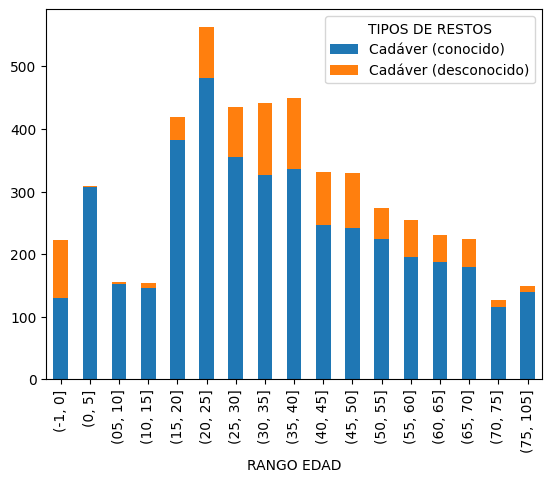

SEXO


TIPOS DE RESTOS,Cadáver (conocido),Cadáver (desconocido)
SEXO,,
Femenino,962,140
Masculino,3187,778


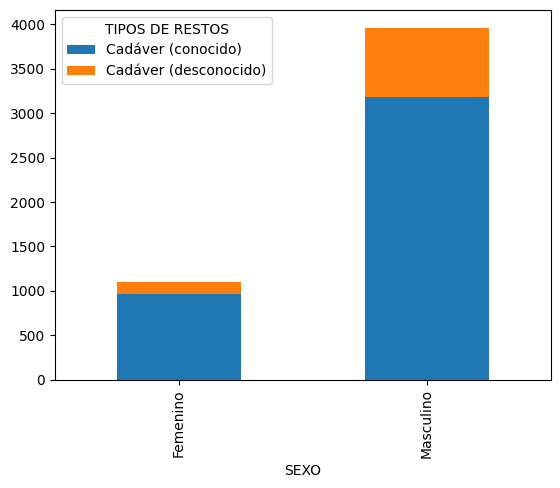

SEMANA


TIPOS DE RESTOS,Cadáver (conocido),Cadáver (desconocido)
SEMANA,,
1.0,95,22
2.0,96,16
3.0,83,20
4.0,91,15
5.0,82,13
6.0,87,14
7.0,89,24
8.0,90,13
9.0,75,17


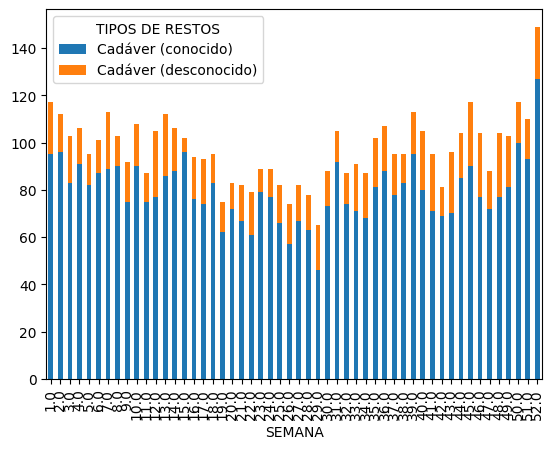

DIA SEMANA


TIPOS DE RESTOS,Cadáver (conocido),Cadáver (desconocido)
DIA SEMANA,,
Domingo,543,101
Jueves,584,132
Lunes,732,187
Martes,619,159
Miércoles,575,113
Sábado,557,99
Viernes,535,129


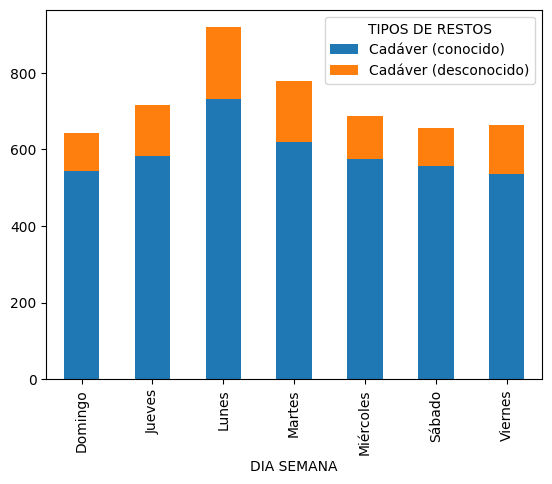

PROCEDENCIA MP Y DEL


TIPOS DE RESTOS,Cadáver (conocido),Cadáver (desconocido)
PROCEDENCIA MP Y DEL,,
Otro,884.0,227.0
HB,426.0,72.0
CR,429.0,41.0
CM,325.0,NaN
HV,245.0,24.0
13A,176.0,51.0
1A,139.0,86.0
HX,166.0,27.0
2A,94.0,88.0


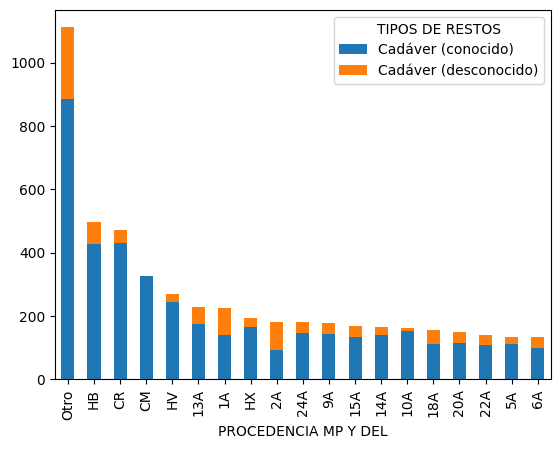

DIAGNOSTICO


TIPOS DE RESTOS,Cadáver (conocido),Cadáver (desconocido)
DIAGNOSTICO,,
Otro,1549.0,282.0
TM,658.0,155.0
TCE,582.0,109.0
TCT,172.0,26.0
BN,101.0,91.0
CVG,135.0,18.0
BN+CH,61.0,75.0
HPAFPC,105.0,6.0
AOVA,87.0,17.0


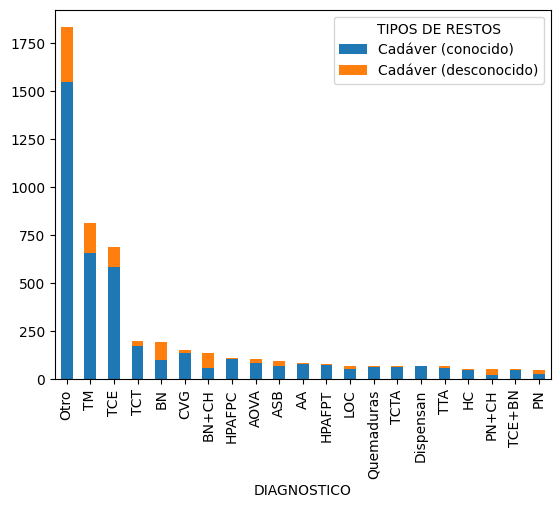

In [8]:
df_counts = dict()

for col in ['RANGO EDAD', 'SEXO', 'SEMANA', 'DIA SEMANA', 'PROCEDENCIA MP Y DEL', 'DIAGNOSTICO']:
    print(col)
    counts = df_cad.pivot_table(index=col, columns='TIPOS DE RESTOS', aggfunc='count')['EDAD']
    if col in ['PROCEDENCIA MP Y DEL', 'DIAGNOSTICO']:
        counts['sum'] = counts.sum(axis=1)
        counts = counts.sort_values(by='sum', ascending=False)
        counts = counts.drop('sum', axis=1)
    df_counts[col] = counts
    display(counts)
    counts.plot(kind='bar', stacked=True)
    plt.show()

### Sexo vs tipo de restos

In [9]:
df_cad[['SEXO','TIPOS DE RESTOS']].value_counts(normalize=True, dropna=False)

SEXO       TIPOS DE RESTOS      
Masculino  Cadáver (conocido)       0.634698
Femenino   Cadáver (conocido)       0.191251
Masculino  Cadáver (desconocido)    0.145822
Femenino   Cadáver (desconocido)    0.026173
NaN        Cadáver (conocido)       0.001496
           Cadáver (desconocido)    0.000561
dtype: float64

In [10]:
df_cad[['TIPOS DE RESTOS','SEXO','EDAD','RANGO EDAD']].dropna().groupby(['TIPOS DE RESTOS','SEXO']).aggregate(mode)

EDAD RANGO EDAD
TIPOS DE RESTOS       SEXO                      
Cadáver (conocido)    Femenino    0.0     (0, 5]
                      Masculino  25.0   (20, 25]
Cadáver (desconocido) Femenino    0.0    (-1, 0]
                      Masculino  35.0   (35, 40]

### Tipo de restos vs procedencia

In [11]:
df_ = df_counts['PROCEDENCIA MP Y DEL'] / 5070
df_['Cadáver (total)'] = df_.sum(axis=1)
df_ = df_.sort_values('Cadáver (total)', ascending=False)
df_.loc['Total'] = df_.sum()
df_

TIPOS DE RESTOS,Cadáver (conocido),Cadáver (desconocido),Cadáver (total)
PROCEDENCIA MP Y DEL,,,
Otro,0.174359,0.044773,0.219132
HB,0.084024,0.014201,0.098225
CR,0.084615,0.008087,0.092702
CM,0.064103,NaN,0.064103
HV,0.048323,0.004734,0.053057
13A,0.034714,0.010059,0.044773
1A,0.027416,0.016963,0.044379
HX,0.032742,0.005325,0.038067
2A,0.018540,0.017357,0.035897


### Tipo de restos vs procedencia

In [12]:
df_counts['PROCEDENCIA MP Y DEL'].divide( df_counts['PROCEDENCIA MP Y DEL'].sum(axis=1), axis=0 ) \
                                 .sort_values('Cadáver (desconocido)', ascending=False)

TIPOS DE RESTOS,Cadáver (conocido),Cadáver (desconocido)
PROCEDENCIA MP Y DEL,,
2A,0.516484,0.483516
1A,0.617778,0.382222
18A,0.724359,0.275641
6A,0.746269,0.253731
20A,0.768212,0.231788
22A,0.771429,0.228571
13A,0.775330,0.224670
Otro,0.795680,0.204320
15A,0.797619,0.202381


### Tipo de restos vs diagnóstico

In [13]:
df_ = df_counts['DIAGNOSTICO'] / 5070
df_['Cadáver (total)'] = df_.sum(axis=1)
df_ = df_.sort_values('Cadáver (total)', ascending=False)
df_.loc['Total'] = df_.sum()
df_

TIPOS DE RESTOS,Cadáver (conocido),Cadáver (desconocido),Cadáver (total)
DIAGNOSTICO,,,
Otro,0.305523,0.055621,0.361144
TM,0.129783,0.030572,0.160355
TCE,0.114793,0.021499,0.136292
TCT,0.033925,0.005128,0.039053
BN,0.019921,0.017949,0.037870
CVG,0.026627,0.003550,0.030178
BN+CH,0.012032,0.014793,0.026824
HPAFPC,0.020710,0.001183,0.021893
AOVA,0.017160,0.003353,0.020513


## Cruces

### Tipo de restos + sexo vs rango de edad

TIPOS DE RESTOS Cadáver (conocido)           Cadáver (desconocido)          
SEXO                      Femenino Masculino              Femenino Masculino
RANGO EDAD                                                                  
(-1, 0]                   0.054054  0.024474              0.278571  0.066838
(0, 5]                    0.119543  0.060559              0.007143  0.000000
(05, 10]                  0.048857  0.032946              0.007143  0.002571
(10, 15]                  0.032225  0.036084              0.028571  0.003856
(15, 20]                  0.088358  0.093191              0.035714  0.042416
(20, 25]                  0.080042  0.127079              0.057143  0.093830
(25, 30]                  0.062370  0.092564              0.121429  0.080977
(30, 35]                  0.058212  0.085033              0.078571  0.133676
(35, 40]                  0.048857  0.090681              0.028571  0.141388
(40, 45]                  0.036383  0.066206              0.035714  0.104113
(45, 50]                  0.051975  0.060245              0.078571  0.098972
(50, 55]                  0.050936  0.054911              0.021429  0.059126
(55, 60]                  0.040541  0.048949              0.021429  0.073265
(60, 65]                  0.047817  0.044556              0.042857  0.046272
(65, 70]                  0.064449  0.037025              0.114286  0.035990
(70, 75]                  0.049896  0.021337              0.028571  0.007712
(75, 105]                 0.065489  0.024161              0.014286  0.008997

<AxesSubplot: xlabel='RANGO EDAD'>

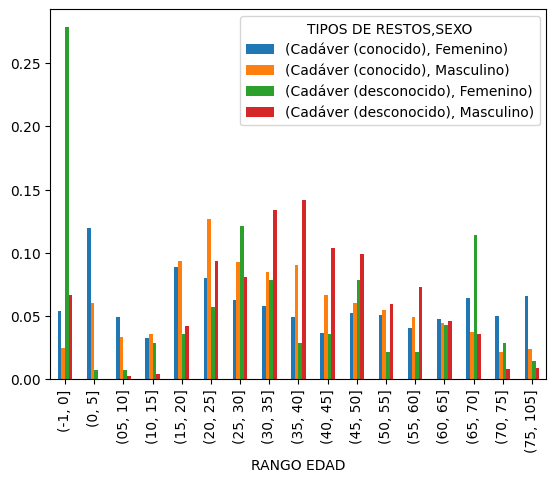

In [14]:
counts = df_cad.pivot_table(index=['RANGO EDAD'], columns=['TIPOS DE RESTOS','SEXO'], aggfunc='count',fill_value=0)['EDAD']
counts = counts / counts.sum()
display(counts)
counts.plot(kind='bar')


### Tipo de restos vs grupo de edad vs diagnostico

In [15]:
pd.pivot_table(df_cad, values='DIAGNOSTICO', index='RANGO EDAD', columns='TIPOS DE RESTOS', aggfunc=top_values_of_series_to_string)

TIPOS DE RESTOS,Cadáver (conocido),Cadáver (desconocido)
RANGO EDAD,,
"(-1, 0]","Otro (0.5077), BN (0.1462), TCE (0.1385), AOVA (0.1154), Quemaduras (0.0308)","Otro (0.5376), BN (0.2688), TCE (0.0645), AOVA (0.0323), HC (0.0215)"
"(0, 5]","Otro (0.3149), TCE (0.1786), TM (0.1429), ASB (0.0649), Quemaduras (0.0649)",TCE (1.0)
"(05, 10]","TCE (0.2566), TM (0.2368), Otro (0.2303), TCT (0.0526), TTA (0.0329)","Otro (0.6667), ASB (0.3333)"
"(10, 15]","Otro (0.3219), TM (0.2192), TCE (0.2055), ASB (0.0616), CVG (0.0342)","Otro (0.2857), TM (0.1429), TCT (0.1429), TCE (0.1429), PN (0.1429)"
"(15, 20]","Otro (0.356), TM (0.144), TCE (0.1414), CVG (0.055), HPAFPC (0.0497)","TM (0.2895), Otro (0.1842), TCE (0.1579), TCT (0.0789), Quemaduras (0.0526)"
"(20, 25]","Otro (0.4212), TM (0.1577), TCE (0.1369), HPAFPC (0.0415), CVG (0.0394)","Otro (0.2963), TM (0.2716), TCE (0.1852), TCT (0.037), ASB (0.037)"
"(25, 30]","Otro (0.4085), TM (0.1465), TCE (0.1296), HPAFPC (0.0563), AA (0.0338)","Otro (0.375), TM (0.2), BN+CH (0.075), ASB (0.0625), BN (0.05)"
"(30, 35]","Otro (0.4343), TM (0.1743), TCE (0.1101), CVG (0.0489), HPAFPC (0.0336)","Otro (0.3304), TM (0.2), TCE (0.1478), BN+CH (0.087), BN (0.0696)"
"(35, 40]","Otro (0.3601), TCE (0.1458), TM (0.1458), TCT (0.0417), BN (0.0327)","Otro (0.2368), TM (0.1842), TCE (0.1491), BN+CH (0.0877), BN (0.0789)"


In [16]:
df_cad.loc[df_cad['RANGO EDAD']=='(-1, 0]', 'DIAGNOSTICO'].value_counts(normalize=True).head()

Otro          0.520179
BN            0.197309
TCE           0.107623
AOVA          0.080717
Quemaduras    0.017937
Name: DIAGNOSTICO, dtype: float64

### Tipo de restos vs grupo de edad vs procedencia

In [17]:
pd.pivot_table(df_cad, values='PROCEDENCIA MP Y DEL', index='RANGO EDAD', columns='TIPOS DE RESTOS', aggfunc=top_values_of_series_to_string)

TIPOS DE RESTOS,Cadáver (conocido),Cadáver (desconocido)
RANGO EDAD,,
"(-1, 0]","Otro (0.3154), 13A (0.0846), 24A (0.0692), 10A (0.0538), HB (0.0462)","Otro (0.2796), 13A (0.1183), 22A (0.1075), 1A (0.0753), 24A (0.0753)"
"(0, 5]","Otro (0.2338), CM (0.0779), 20A (0.0649), 24A (0.0649), 1A (0.0617)",CR (1.0)
"(05, 10]","Otro (0.1513), HB (0.125), CR (0.1184), CM (0.0724), HV (0.0592)","15A (0.3333), 18A (0.3333), Otro (0.3333)"
"(10, 15]","Otro (0.2466), HB (0.1027), HV (0.089), CR (0.089), 13A (0.0753)","22A (0.2857), 5A (0.1429), Otro (0.1429), HX (0.1429), 13A (0.1429)"
"(15, 20]","Otro (0.1911), CR (0.1309), HB (0.1099), HV (0.0602), CM (0.055)","Otro (0.3158), 13A (0.1053), HB (0.1053), 20A (0.1053), 1A (0.0789)"
"(20, 25]","Otro (0.2303), CR (0.1286), CM (0.1017), HB (0.0664), HV (0.0602)","Otro (0.358), 2A (0.0864), 13A (0.0864), 14A (0.0617), 18A (0.0617)"
"(25, 30]","Otro (0.2535), HB (0.1127), CR (0.1099), CM (0.0873), HV (0.0479)","Otro (0.275), HB (0.075), 20A (0.075), 13A (0.0625), 15A (0.0625)"
"(30, 35]","Otro (0.2294), CR (0.1101), HB (0.1009), CM (0.0795), HV (0.0612)","Otro (0.1565), 2A (0.1478), HB (0.1304), 1A (0.113), 22A (0.0522)"
"(35, 40]","Otro (0.1786), HB (0.125), CR (0.1131), CM (0.0863), 14A (0.0595)","Otro (0.2895), 1A (0.1053), HB (0.0965), 2A (0.0877), 9A (0.0526)"


In [18]:
df_cad.loc[df_cad['RANGO EDAD']=='(-1, 0]', 'PROCEDENCIA MP Y DEL'].value_counts(normalize=True).head()

Otro    0.300448
13A     0.098655
24A     0.071749
22A     0.067265
9A      0.053812
Name: PROCEDENCIA MP Y DEL, dtype: float64

### Sexo + diagnostico vs procedencia

In [19]:
df_ = df_cad[df_cad['TIPOS DE RESTOS']=='Cadáver (conocido)']
df_[['SEXO','DIAGNOSTICO','PROCEDENCIA MP Y DEL']].groupby(['SEXO','DIAGNOSTICO']).aggregate(
    Frecuencia=pd.NamedAgg(column='PROCEDENCIA MP Y DEL', aggfunc='count'),
    Procedencia=pd.NamedAgg(column='PROCEDENCIA MP Y DEL', aggfunc=top_values_of_series_to_string)
    )

Frecuencia  \
SEXO      DIAGNOSTICO               
Femenino  AA                    6   
          AOVA                 26   
          ASB                  14   
          BN                   33   
          BN+CH                11   
          CVG                  48   
          Dispensan            23   
          HC                   19   
          HPAFPC               13   
          HPAFPT                6   
          LOC                   9   
          Otro                404   
          PN                    5   
          PN+CH                 2   
          Quemaduras           19   
          TCE                 118   
          TCE+BN                8   
          TCT                  44   
          TCTA                 15   
          TM                  173   
          TTA                  21   
Masculino AA                   79   
          AOVA                 70   
          ASB                  65   
          BN                   73   
          BN+CH                53   
          CVG                  92   
          Dispensan            57   
          HC                   30   
          HPAFPC               99   
          HPAFPT               74   
          LOC                  46   
          Otro               1248   
          PN                   26   
          PN+CH                24   
          Quemaduras           48   
          TCE                 502   
          TCE+BN               42   
          TCT                 136   
          TCTA                 55   
          TM                  516   
          TTA                  44   

                                                                                Procedencia  
SEXO      DIAGNOSTICO                                                                        
Femenino  AA           Otro (0.3333), CM (0.1667), 20A (0.1667), 22A (0.1667), 18A (0.1667)  
          AOVA         Otro (0.1923), CM (0.1923), 22A (0.1538), 10A (0.1154), 24A (0.0769)  
          ASB           Otro (0.2143), CR (0.1429), 13A (0.1429), 24A (0.1429), 5A (0.0714)  
          BN            Otro (0.3939), 10A (0.1212), HV (0.0909), HB (0.0909), 24A (0.0606)  
          BN+CH          Otro (0.2727), 6A (0.1818), HB (0.1818), 20A (0.0909), CR (0.0909)  
          CVG              Otro (0.1667), HV (0.125), CR (0.1042), CM (0.1042), 6A (0.0833)  
          Dispensan       Otro (0.3913), 22A (0.1304), 13A (0.087), CM (0.087), 10A (0.087)  
          HC             HB (0.2632), Otro (0.2632), CM (0.1053), 24A (0.1053), HV (0.1053)  
          HPAFPC         Otro (0.3846), CR (0.1538), HB (0.1538), CM (0.0769), 14A (0.0769)  
          HPAFPT       15A (0.3333), 1A (0.1667), 24A (0.1667), Otro (0.1667), 13A (0.1667)  
          LOC           HV (0.2222), 10A (0.2222), Otro (0.2222), 18A (0.1111), 2A (0.1111)  
          Otro            Otro (0.1901), HB (0.1432), CM (0.1111), HV (0.0667), CR (0.0642)  
          PN                                                Otro (0.4), CR (0.4), 13A (0.2)  
          PN+CH                                                       13A (0.5), Otro (0.5)  
          Quemaduras     Otro (0.3158), 9A (0.2105), HB (0.1053), CM (0.1053), 20A (0.0526)  
          TCE             Otro (0.1441), CR (0.1186), HB (0.1102), CM (0.1017), HX (0.0932)  
          TCE+BN                 CM (0.25), HB (0.125), 6A (0.125), 10A (0.125), 5A (0.125)  
          TCT            CR (0.2045), Otro (0.1818), HB (0.1136), CM (0.0909), 13A (0.0682)  
          TCTA            Otro (0.2667), 5A (0.1333), HX (0.1333), HB (0.1333), HV (0.0667)  
          TM           Otro (0.2428), CR (0.1618), 14A (0.0751), 18A (0.0462), 13A (0.0462)  
          TTA            CR (0.2381), Otro (0.1429), HX (0.1429), 10A (0.0952), CM (0.0952)  
Masculino AA            Otro (0.3291), 1A (0.1013), 15A (0.0886), 9A (0.0633), 14A (0.0633)  
          AOVA             Otro (0.2714), 2A (0.1), 13A (0.0857), 22A (0.0714), 6A (0.0714)  
          ASB            Otro (0.4), 15A (0.

### Sexo + tipo de restos vs diagnostico

In [20]:
df_ = pd.pivot_table(df_cad.fillna('S-d'), index='DIAGNOSTICO', columns=['SEXO','TIPOS DE RESTOS'], aggfunc='count')['EDAD']
df_

SEXO                      Femenino                                Masculino  \
TIPOS DE RESTOS Cadáver (conocido) Cadáver (desconocido) Cadáver (conocido)   
DIAGNOSTICO                                                                   
AA                             6.0                   1.0               79.0   
AOVA                          26.0                   2.0               70.0   
ASB                           14.0                   3.0               65.0   
BN                            33.0                  24.0               73.0   
BN+CH                         11.0                   8.0               53.0   
CVG                           48.0                   3.0               92.0   
Dispensan                     23.0                   NaN               57.0   
HC                            19.0                   3.0               30.0   
HPAFPC                        13.0                   1.0               99.0   
HPAFPT                         6.0                   NaN               74.0   
LOC                            9.0                   4.0               46.0   
Otro                         405.0                  46.0             1248.0   
PN                             5.0                   4.0               26.0   
PN+CH                          2.0                   1.0               24.0   
Quemaduras                    19.0                   3.0               48.0   
S-d                            5.0                   NaN               16.0   
TCE                          118.0                  12.0              502.0   
TCE+BN                         8.0                   NaN               42.0   
TCT                           44.0                   4.0              136.0   
TCTA                          15.0                   1.0               55.0   
TM                           173.0                  20.0              516.0   
TTA                           21.0                   NaN               44.0   

SEXO                                                 S-d                        
TIPOS DE RESTOS Cadáver (desconocido) Cadáver (conocido) Cadáver (desconocido)  
DIAGNOSTICO                                                                     
AA                                6.0                NaN                   NaN  
AOVA                             15.0                NaN                   NaN  
ASB                              18.0                NaN                   NaN  
BN                               67.0                NaN                   NaN  
BN+CH                            67.0                NaN                   NaN  
CVG                              15.0                NaN                   NaN  
Dispensan                         NaN                1.0                   NaN  
HC                                3.0                NaN                   NaN  
HPAFPC                            5.0                NaN                   NaN  
HPAFPT                            5.0                NaN                   NaN  
LOC                              15.0                NaN                   NaN  
Otro                            235.0                1.0                   2.0  
PN                               19.0                NaN                   NaN  
PN+CH                            28.0                NaN                   NaN  
Quemaduras                        5.0                NaN                   NaN  
S-d                               7.0                6.0                   1.0  
TCE                              97.0                NaN                   NaN  
TCE+BN                            5.0                NaN                   NaN  
TCT                              22.0                NaN                   NaN  
TCTA                              4.0                NaN                   NaN  
TM                              135.0                NaN                   NaN  
TTA                               7.0                NaN                   NaN

## Fechas

In [21]:
col = 'FECHA'
df_cad.groupby(['TIPOS DE RESTOS','SEXO']).aggregate(
      grupo_total = pd.NamedAgg(column='FECHA', aggfunc="size"),
      grupo_fecha = pd.NamedAgg(column='FECHA', aggfunc="count"),
      fecha_min   = pd.NamedAgg(column='FECHA', aggfunc="min"),
      fecha_max   = pd.NamedAgg(column='FECHA', aggfunc="max"),
      fecha_moda  = pd.NamedAgg(column='FECHA', aggfunc=mode),
      semana_min  = pd.NamedAgg(column='SEMANA', aggfunc="min"),
      semana_max  = pd.NamedAgg(column='SEMANA', aggfunc="max"),
      semana_moda = pd.NamedAgg(column='SEMANA', aggfunc=mode),
      diasem_moda = pd.NamedAgg(column='DIA SEMANA', aggfunc=mode),
      )


grupo_total  grupo_fecha  fecha_min  \
TIPOS DE RESTOS       SEXO                                             
Cadáver (conocido)    Femenino          1023         1023 1974-01-01   
                      Masculino         3395         3385 1974-01-01   
Cadáver (desconocido) Femenino           140          140 1974-01-08   
                      Masculino          780          780 1974-01-01   

                                 fecha_max fecha_moda  semana_min  semana_max  \
TIPOS DE RESTOS       SEXO                                                      
Cadáver (conocido)    Femenino  1974-12-31 1974-01-20         1.0        52.0   
                      Masculino 1974-12-31 1974-12-09         1.0        52.0   
Cadáver (desconocido) Femenino  1974-12-31 1974-07-12         1.0        52.0   
                      Masculino 1974-12-31 1974-03-18         1.0        52.0   

                                 semana_moda diasem_moda  
TIPOS DE RESTOS       SEXO                                
Cadáver (conocido)    Femenino          52.0       Lunes  
                      Masculino         52.0       Lunes  
Cadáver (desconocido) Femenino          12.0      Martes  
                      Masculino         45.0       Lunes

### Cadaveres por semana

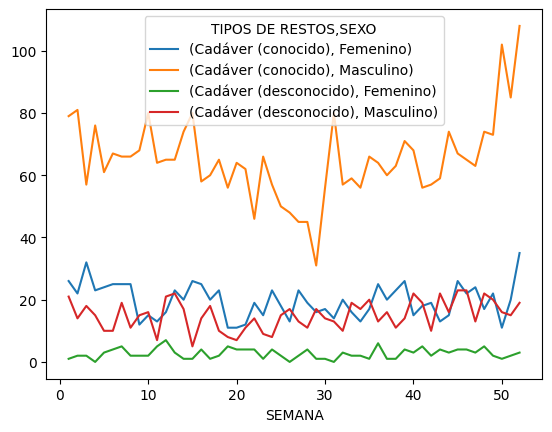

In [22]:
df_cad_sem = pd.pivot_table(df_cad, values='FECHA', index='SEMANA', columns=['TIPOS DE RESTOS','SEXO'], aggfunc='count').fillna(0)
df_cad_sem.plot()
plt.show()

df_cad_sem['Total'] = df_cad_sem.sum(axis=1)

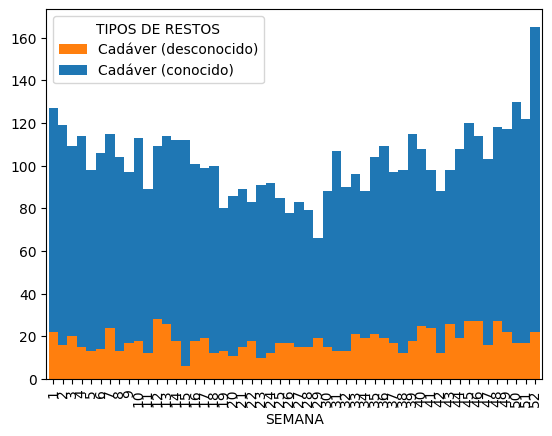

In [23]:
df_ = pd.pivot_table(df_cad, values='FECHA', index='SEMANA', columns=['TIPOS DE RESTOS'], aggfunc='count').fillna(0) 
df_.index = [round(i) for i in df_.index]
df_.index.name = 'SEMANA'
df_ = df_[['Cadáver (desconocido)','Cadáver (conocido)',]]
df_.plot.bar(stacked=True, width=1.0, color=['tab:orange','tab:blue'])
plt.show()

In [24]:
df_cad_sem.corr()

TIPOS DE RESTOS                 Cadáver (conocido)            \
SEXO                                      Femenino Masculino   
TIPOS DE RESTOS       SEXO                                     
Cadáver (conocido)    Femenino            1.000000  0.198899   
                      Masculino           0.198899  1.000000   
Cadáver (desconocido) Femenino            0.023771 -0.129335   
                      Masculino           0.070524  0.130815   
Total                                     0.512399  0.889490   

TIPOS DE RESTOS                 Cadáver (desconocido)               Total  
SEXO                                         Femenino Masculino            
TIPOS DE RESTOS       SEXO                                                 
Cadáver (conocido)    Femenino               0.023771  0.070524  0.512399  
                      Masculino             -0.129335  0.130815  0.889490  
Cadáver (desconocido) Femenino               1.000000  0.035994  0.013434  
                      Masculino              0.035994  1.000000  0.415668  
Total                                        0.013434  0.415668  1.000000

### Distribucion ingreso de cadaveres por semana

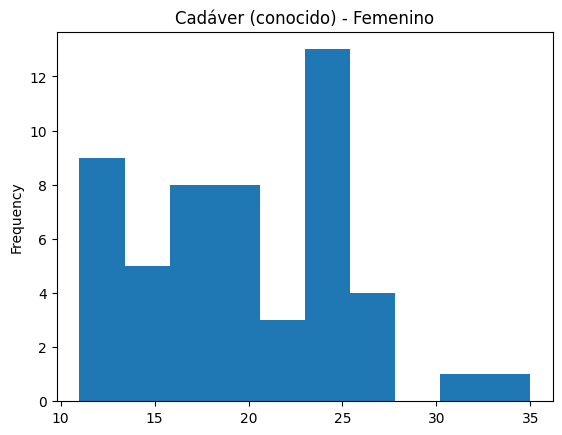

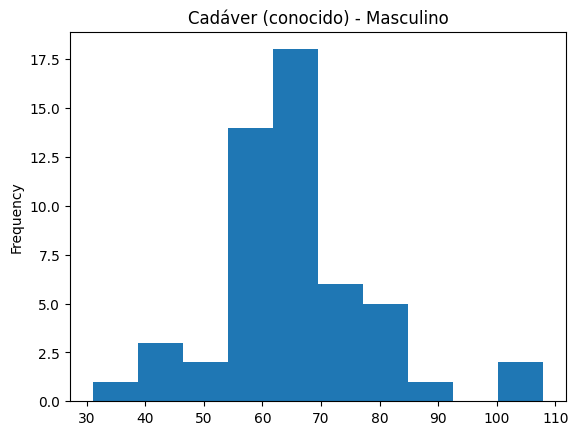

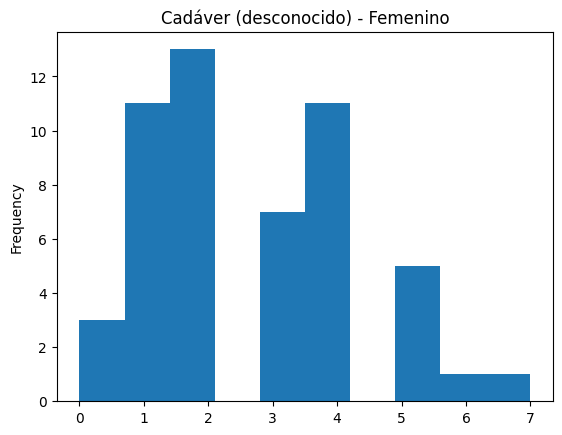

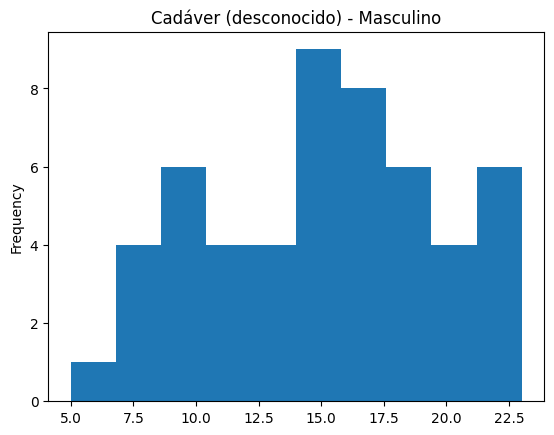

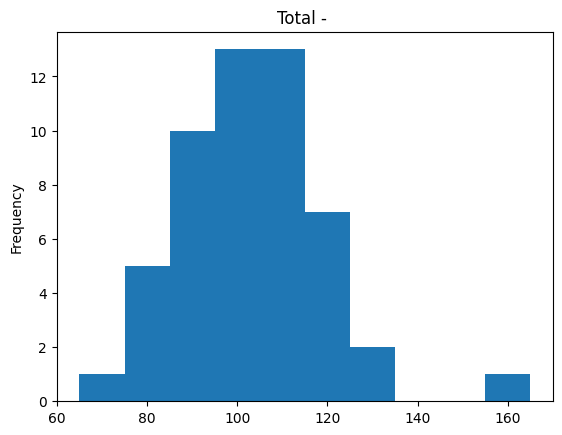

In [25]:
for col in df_cad_sem.columns:
    df_cad_sem[col].plot.hist(title=' - '.join(col))
    plt.show()

### Outliers ingreso de cadaveres por semana

In [26]:
df_cad_sem.agg(['mean', 'std'])

TIPOS DE RESTOS Cadáver (conocido)            Cadáver (desconocido)  \
SEXO                      Femenino  Masculino              Femenino   
mean                     19.673077  65.096154              2.692308   
std                       5.458295  13.177907              1.627442   

TIPOS DE RESTOS                  Total  
SEXO             Masculino              
mean             15.000000  102.461538  
std               4.686233   16.488215

In [27]:
df_zscore = df_cad_sem.apply(zscore)

thr_zscore = 2
print('Outliers ingreso por semana\t(mas de {} std)'.format(thr_zscore))
display( df_cad_sem.mask(df_zscore < thr_zscore).dropna(how='all') )

Outliers ingreso por semana	(mas de 2 std)


TIPOS DE RESTOS Cadáver (conocido)           Cadáver (desconocido)            \
SEXO                      Femenino Masculino              Femenino Masculino   
SEMANA                                                                         
3.0                           32.0       NaN                   NaN       NaN   
12.0                           NaN       NaN                   7.0       NaN   
36.0                           NaN       NaN                   6.0       NaN   
50.0                           NaN     102.0                   NaN       NaN   
52.0                          35.0     108.0                   NaN       NaN   

TIPOS DE RESTOS  Total  
SEXO                    
SEMANA                  
3.0                NaN  
12.0               NaN  
36.0               NaN  
50.0               NaN  
52.0             165.0

### Cadaveres por dia

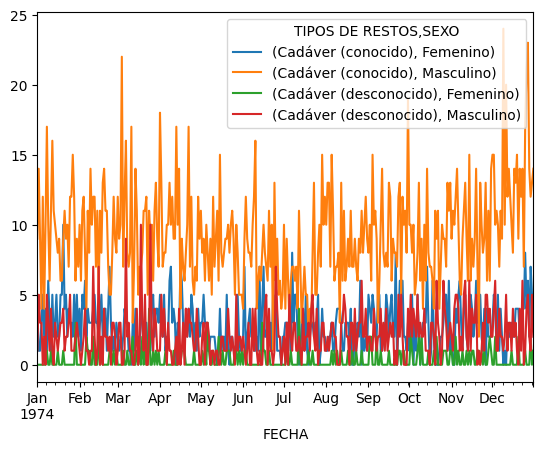

In [28]:
df_cad_dia = pd.pivot_table(df_cad, values='SEMANA', index='FECHA', columns=['TIPOS DE RESTOS','SEXO'], aggfunc='count').fillna(0)

df_cad_dia.plot()
plt.show()

df_cad_dia['Total'] = df_cad_dia.sum(axis=1)

In [29]:
df_cad_dia.corr()

TIPOS DE RESTOS                 Cadáver (conocido)            \
SEXO                                      Femenino Masculino   
TIPOS DE RESTOS       SEXO                                     
Cadáver (conocido)    Femenino            1.000000  0.038025   
                      Masculino           0.038025  1.000000   
Cadáver (desconocido) Femenino           -0.037596 -0.043442   
                      Masculino           0.036941  0.183030   
Total                                     0.418050  0.828575   

TIPOS DE RESTOS                 Cadáver (desconocido)               Total  
SEXO                                         Femenino Masculino            
TIPOS DE RESTOS       SEXO                                                 
Cadáver (conocido)    Femenino              -0.037596  0.036941  0.418050  
                      Masculino             -0.043442  0.183030  0.828575  
Cadáver (desconocido) Femenino               1.000000  0.069796  0.122757  
                      Masculino              0.069796  1.000000  0.535356  
Total                                        0.122757  0.535356  1.000000

### Distribucion ingreso de cadaveres por día

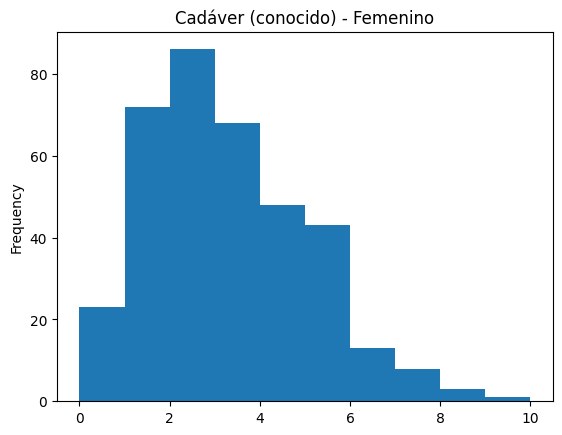

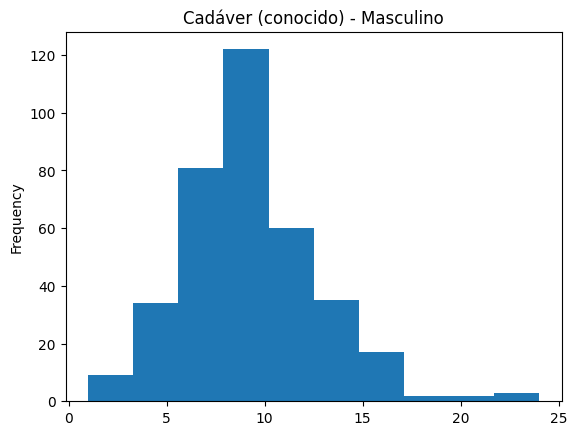

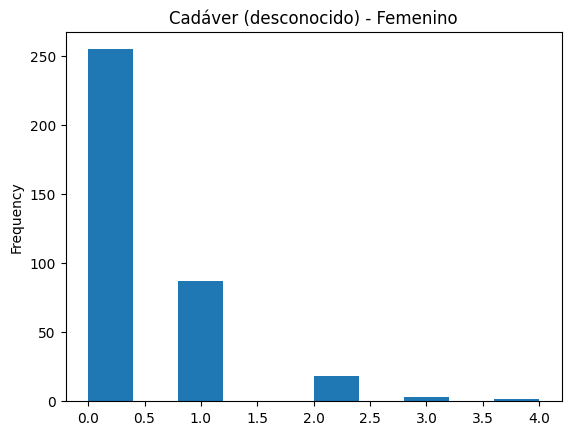

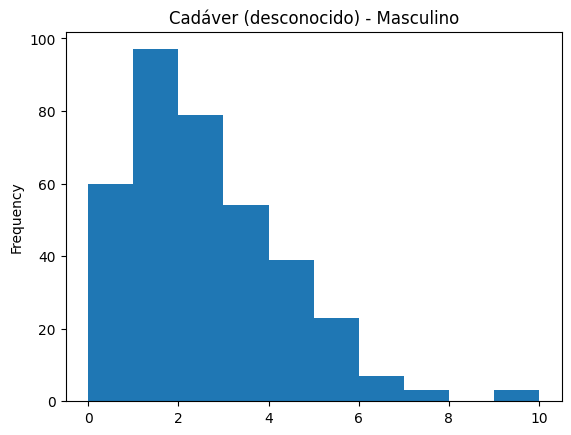

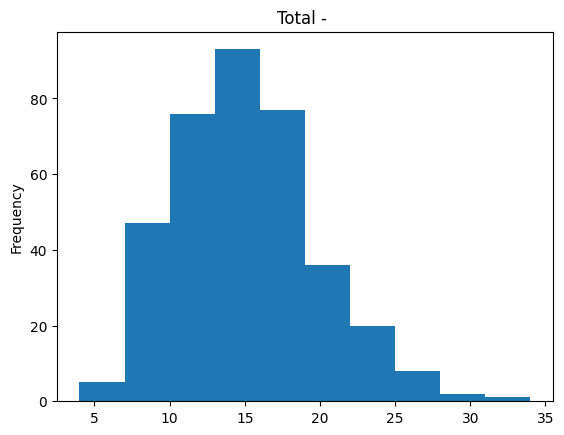

In [30]:
for col in df_cad_dia.columns:
    df_cad_dia[col].plot.hist(title=' - '.join(col))
    plt.show()

### Outliers ingreso de cadaveres por día

In [31]:
df_cad_dia.agg(['mean', 'std', mode, 'min', 'max'])

TIPOS DE RESTOS Cadáver (conocido)            Cadáver (desconocido)  \
SEXO                      Femenino  Masculino              Femenino   
mean                      2.802740   9.273973              0.383562   
std                       1.781928   3.516290              0.671846   
mode                      2.000000   7.000000              0.000000   
min                       0.000000   1.000000              0.000000   
max                      10.000000  24.000000              4.000000   

TIPOS DE RESTOS                 Total  
SEXO             Masculino             
mean              2.136986  14.597260  
std               1.747173   4.676278  
mode              1.000000  14.000000  
min               0.000000   4.000000  
max              10.000000  34.000000

In [32]:
df_cad_dia['Total'].sort_values()

FECHA
1974-06-29     4.0
1974-06-23     6.0
1974-07-19     6.0
1974-07-14     6.0
1974-03-23     6.0
              ... 
1974-09-30    26.0
1974-12-25    27.0
1974-03-07    28.0
1974-12-26    29.0
1974-12-27    34.0
Name: Total, Length: 365, dtype: float64

In [33]:
df_zscore = df_cad_dia.apply(zscore)

thr_zscore = 2
print('Outliers ingreso por semana\t(mas de {} std)'.format(thr_zscore))
display( df_cad_dia.mask(df_zscore < thr_zscore).dropna(how='all') )


Outliers ingreso por semana	(mas de 2 std)


TIPOS DE RESTOS Cadáver (conocido)           Cadáver (desconocido)            \
SEXO                      Femenino Masculino              Femenino Masculino   
FECHA                                                                          
1974-01-08                     NaN      17.0                   NaN       NaN   
1974-01-20                    10.0       NaN                   NaN       NaN   
1974-01-29                     NaN       NaN                   3.0       NaN   
1974-02-06                     NaN       NaN                   2.0       NaN   
1974-02-11                     NaN       NaN                   2.0       7.0   
1974-02-15                     NaN       NaN                   2.0       7.0   
1974-02-23                     7.0       NaN                   NaN       NaN   
1974-03-04                     NaN      22.0                   NaN       NaN   
1974-03-07                     NaN       NaN                   NaN       9.0   
1974-03-11                     NaN      17.0                   NaN       NaN   
1974-03-12                     NaN       NaN                   2.0       NaN   
1974-03-18                     NaN       NaN                   NaN      10.0   
1974-03-19                     NaN       NaN                   2.0       NaN   
1974-03-24                     NaN       NaN                   4.0       NaN   
1974-03-25                     NaN       NaN                   NaN      10.0   
1974-04-01                     NaN      18.0                   NaN       NaN   
1974-04-09                     7.0       NaN                   NaN       NaN   
1974-04-13                     NaN      17.0                   NaN       NaN   
1974-04-16                     7.0       NaN                   NaN       NaN   
1974-04-22                     NaN      17.0                   NaN       NaN   
1974-05-06                     NaN       NaN                   3.0       NaN   
1974-05-14                     NaN       NaN                   2.0       NaN   
1974-06-02                     7.0       NaN                   NaN       NaN   
1974-06-13                     7.0       NaN                   NaN       NaN   
1974-06-15                     NaN       NaN                   3.0       NaN   
1974-06-16                     7.0       NaN                   NaN       NaN   
1974-06-25                     NaN       NaN                   NaN       7.0   
1974-07-07                     8.0       NaN                   NaN       NaN   
1974-07-12                     NaN       NaN                   4.0       NaN   
1974-08-27                     NaN       NaN                   NaN       6.0   
1974-09-02                     NaN       NaN                   2.0       NaN   
1974-09-03                     NaN       NaN                   2.0       NaN   
1974-09-07                     NaN       NaN                   2.0       NaN   
1974-09-21                     8.0       NaN                   NaN       NaN   
1974-09-30                     NaN      19.0                   NaN       NaN   
1974-10-02                     NaN       NaN                   2.0       NaN   
1974-10-08                     NaN       NaN                   2.0       NaN   
1974-10-10                     NaN       NaN                   2.0       NaN   
1974-10-14                     7.0       NaN                   NaN       NaN   
1974-10-21                     NaN       NaN                   2.0       6.0   
1974-10-26                     NaN       NaN                   NaN       6.0   
1974-11-04                     NaN       NaN                   2.0       NaN   
1974-11-11                     NaN       NaN                   NaN       6.0   
1974-11-14                     NaN       NaN                   NaN       6.0   
1974-11-19                     NaN       NaN                   NaN       NaN   
1974-11-29                     NaN       NaN                   2.0       NaN   
1974-12-02                     NaN       NaN                   NaN       NaN   


In [34]:
outliers = df_cad_dia[df_cad_dia['Total']>=24].index
outliers

DatetimeIndex(['1974-01-08', '1974-01-20', '1974-02-11', '1974-03-07',
               '1974-04-01', '1974-04-22', '1974-09-30', '1974-11-11',
               '1974-11-14', '1974-11-19', '1974-12-02', '1974-12-09',
               '1974-12-11', '1974-12-23', '1974-12-25', '1974-12-26',
               '1974-12-27'],
              dtype='datetime64[ns]', name='FECHA', freq=None)

In [35]:
df_cad[df_cad['FECHA'].isin(outliers)][['FECHA','DIA SEMANA']].drop_duplicates()

,FECHA,DIA SEMANA
10,1974-01-08,Martes
18,1974-01-20,Domingo
35,1974-02-11,Lunes
77,1974-04-01,Lunes
232,1974-09-30,Lunes
283,1974-11-19,Martes
291,1974-11-14,Jueves
297,1974-12-02,Lunes
305,1974-12-09,Lunes
306,1974-12-11,Miércoles


### Outliers ingreso por día resumen

### Verificar si poisson

('Cadáver (conocido)', 'Femenino')
	chisquare-score: 13.397842054874976
	critical value: 18.307038053275146
	p-value: 0.20227056382076913
The data follows a poisson distribution.


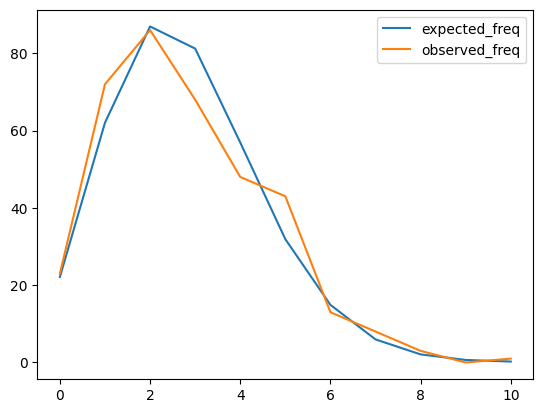




('Cadáver (conocido)', 'Masculino')
	chisquare-score: 142.4327486314708
	critical value: 36.41502850180731
	p-value: 0.0
The data does NOT follow a poisson distribution.


,varname,prob_dist,expected_freq,observed_freq,chi_square
0,0,0.000094,0.034250,0.0,0.034250
1,1,0.000870,0.317631,1.0,1.465934
2,2,0.004035,1.472853,2.0,0.188671
3,3,0.012474,4.553066,6.0,0.459826
4,4,0.028921,10.556252,13.0,0.565722
5,5,0.053643,19.579678,21.0,0.103031
6,6,0.082914,30.263565,36.0,1.087337
7,7,0.109849,40.094782,45.0,0.600107
8,8,0.127342,46.479739,38.0,1.547039
9,9,0.131218,47.894648,43.0,0.500214


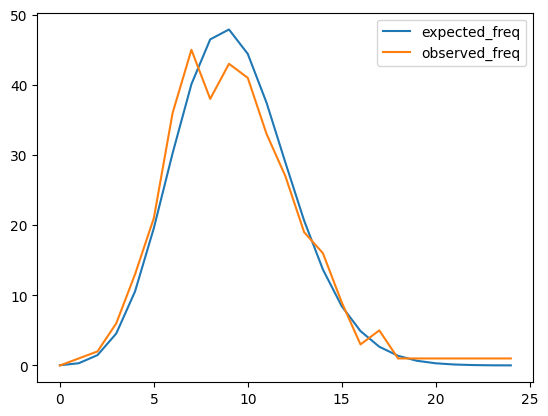




('Cadáver (desconocido)', 'Femenino')
	chisquare-score: 13.815010212063404
	critical value: 9.487729036781154
	p-value: 0.007909483597386857
The data does NOT follow a poisson distribution.


,varname,prob_dist,expected_freq,observed_freq,chi_square
0,0,0.681430,248.721976,255,0.158464
1,1,0.261370,95.400210,87,0.739658
2,2,0.050126,18.295931,18,0.004787
3,3,0.006409,2.339206,3,0.186666
4,4,0.000665,0.242678,2,12.725436


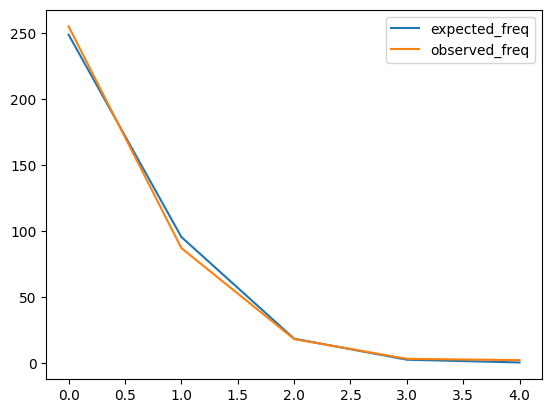




('Cadáver (desconocido)', 'Masculino')
	chisquare-score: 159.73664324007285
	critical value: 18.307038053275146
	p-value: 0.0
The data does NOT follow a poisson distribution.


,varname,prob_dist,expected_freq,observed_freq,chi_square
0,0,0.118010,43.073633,60.0,6.651445
1,1,0.252186,92.047764,97.0,0.266434
2,2,0.269459,98.352406,79.0,3.807895
3,3,0.191943,70.059248,54.0,3.681162
4,4,0.102545,37.428913,39.0,0.065947
5,5,0.043827,15.997015,23.0,3.065684
6,6,0.015610,5.697567,7.0,0.297729
7,7,0.004765,1.739375,3.0,0.913648
8,8,0.001273,0.464627,0.0,0.464627
9,9,0.000302,0.110323,1.0,7.174656


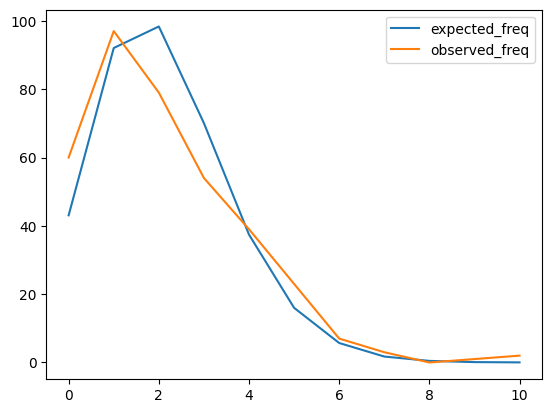




('Total', '')
	chisquare-score: 338.03885427506077
	critical value: 48.602367367294164
	p-value: 0.0
The data does NOT follow a poisson distribution.


,varname,prob_dist,expected_freq,observed_freq,chi_square
0,0,4.576046e-07,0.000167,0.0,0.000167
1,1,6.679774e-06,0.002438,0.0,0.002438
2,2,4.875320e-05,0.017795,0.0,0.017795
3,3,2.372210e-04,0.086586,0.0,0.086586
4,4,8.656943e-04,0.315978,1.0,1.480751
5,5,2.527353e-03,0.922484,0.0,0.922484
6,6,6.148739e-03,2.244290,4.0,1.373494
7,7,1.282211e-02,4.680068,13.0,14.790652
8,8,2.339595e-02,8.539522,15.0,4.887601
9,9,3.794631e-02,13.850403,19.0,1.914627


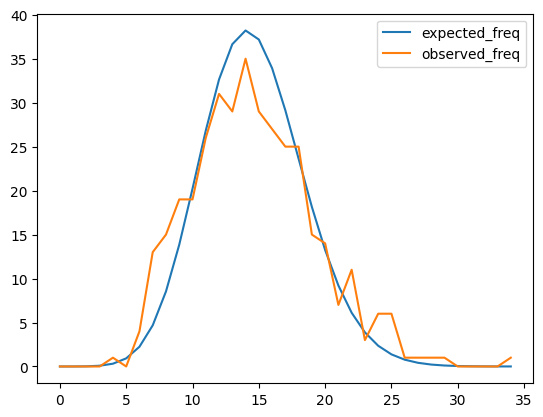

In [36]:
def goof_fit_with_poisson(series):
    from scipy.stats import chi2
    from math import exp, factorial
    
    obs_data = series.value_counts().sort_index()
    poisson_n = obs_data.sum()
    poisson_u = series.mean()
    poisson_k = int(series.max())
    #display(obs_data)
    #print("n={}\tu={}\tk={}".format(poisson_n, poisson_u, poisson_k))

    df_goodfit = pd.DataFrame(index=range(poisson_k+1), columns=['varname','prob_dist','expected_freq','observed_freq'])
    df_goodfit['varname'] = df_goodfit.index
    df_goodfit['prob_dist'] = df_goodfit['varname'].apply(lambda k: exp(-poisson_u) * poisson_u**k / factorial(k))
    df_goodfit.loc[poisson_k,'prob_dist'] = 1-df_goodfit.loc[range(poisson_k),'prob_dist'].sum()
    df_goodfit['expected_freq'] = df_goodfit['prob_dist'] * poisson_n
    df_goodfit['observed_freq'] = obs_data
    df_goodfit = df_goodfit.fillna(0) 
    df_goodfit['chi_square'] = df_goodfit.apply(lambda r: (r['observed_freq']-r['expected_freq'])**2/r['expected_freq'], axis=1 )
    df_goodfit
    
    alpha = 0.05 # significance level
    chi_square = df_goodfit['chi_square'].sum()
    p_value = 1 - chi2.cdf(chi_square, df_goodfit['varname'].nunique() - 1)
    critical_value = chi2.ppf(1-alpha, df_goodfit['varname'].nunique() - 1)
    print("\tchisquare-score: {}\n\tcritical value: {}\n\tp-value: {}" \
          .format(chi_square, critical_value, p_value))
    
    if chi_square > critical_value or p_value <= alpha:
        print("The data does NOT follow a poisson distribution.")
        conclusion = False
    else: 
        print("The data follows a poisson distribution.")
        conclusion = True
        
    
    return conclusion, df_goodfit

for col in df_cad_dia.columns:
    print(col)
    res, df_ = goof_fit_with_poisson( df_cad_dia[col] )
    if not res: 
        display(df_)
    df_[['expected_freq','observed_freq']].plot()
    plt.show()
    print('\n\n')

### Outliers de nuevo

In [37]:
dia_outliers = {('Cadáver (desconocido)', 'Femenino'):4,
                ('Cadáver (conocido)', 'Masculino'):23,
                ('Cadáver (desconocido)', 'Masculino'):9,
                ('Total', ''):25 }
for col, thr in dia_outliers.items():
    print(col)
    outliers = df_cad_dia[df_cad_dia[col]>=thr].index
    df_ = df_cad[df_cad['FECHA'].isin(outliers)]
    if col!=('Total', ''):
        df_ = df_[(df_['TIPOS DE RESTOS']==col[0]) & (df_['SEXO']==col[1])]
    df_=df_.groupby('FECHA').agg(lambda s: top_values_of_series_to_string(s, normalize=False))
    display(df_)
    print('\n')

('Cadáver (desconocido)', 'Femenino')


,TIPOS DE RESTOS,EDAD,RANGO EDAD,SEXO,SEMANA,DIA SEMANA,AVERIGUACION PREVIA CON PROCEDENCIA,PROCEDENCIA MP Y DEL,DIAGNOSTICO
FECHA,,,,,,,,,
1974-03-24,Cadáver (desconocido) (4),0.0 (4),"(-1, 0] (4)",Femenino (4),12.0 (4),Domingo (4),"8A_124 (1), 13A_531 (1), 13A_1208 (1), 24A_786 (1)","13A (2), Otro (1), 24A (1)","Otro (3), BN (1)"
1974-07-12,Cadáver (desconocido) (4),"0.0 (2), 68.0 (1), 6.0 (1)","(-1, 0] (2), (65, 70] (1), (05, 10] (1)",Femenino (4),28.0 (4),Viernes (4),"19A_600 (1), 24A_1091 (1), 10A_825 (1), 18A_887 (1)","Otro (1), 24A (1), 10A (1), 18A (1)","Otro (2), HC (1), AOVA (1)"




('Cadáver (conocido)', 'Masculino')


,TIPOS DE RESTOS,EDAD,RANGO EDAD,SEXO,SEMANA,DIA SEMANA,AVERIGUACION PREVIA CON PROCEDENCIA,PROCEDENCIA MP Y DEL,DIAGNOSTICO
FECHA,,,,,,,,,
1974-12-09,Cadáver (conocido) (24),"nan (4), 22.0 (3), 0.0 (2), 35.0 (2), 1.0 (1)","nan (4), (0, 5] (3), (30, 35] (3), (20, 25] (3), (-1, 0] (2)",Masculino (24),50.0 (24),Lunes (24),"10A_1489 (1), HB_1752 (1), HX_889 (1), 20A_1349 (1), 10A_1492 (1)","Otro (6), HB (4), 20A (3), 24A (3), 10A (2)","Otro (12), TCE (5), BN (2), TM (2), TCT (1)"
1974-12-27,Cadáver (conocido) (23),"50.0 (4), 39.0 (4), nan (2), 40.0 (2), 25.0 (2)","(35, 40] (8), (45, 50] (4), (20, 25] (3), nan (2), (30, 35] (2)",Masculino (23),52.0 (23),Viernes (23),"20A_1420 (1), 15A_2268 (1), 1A_2233 (1), 6A_1815 (1), 24A_2066 (1)","24A (4), 15A (3), CR (3), Otro (2), 1A (2)","Otro (10), TM (3), BN (2), AOVA (2), ASB (1)"




('Cadáver (desconocido)', 'Masculino')


,TIPOS DE RESTOS,EDAD,RANGO EDAD,SEXO,SEMANA,DIA SEMANA,AVERIGUACION PREVIA CON PROCEDENCIA,PROCEDENCIA MP Y DEL,DIAGNOSTICO
FECHA,,,,,,,,,
1974-03-07,Cadáver (desconocido) (9),"50.0 (2), 45.0 (1), 40.0 (1), 60.0 (1), 76.0 (1)","(45, 50] (2), (25, 30] (2), (40, 45] (1), (35, 40] (1), (55, 60] (1)",Masculino (9),10.0 (9),Jueves (9),"10A_257 (1), CR_248 (1), CR_246 (1), CR_247 (1), 7A_332 (1)","CR (3), 13A (2), 10A (1), Otro (1), 2A (1)","BN+CH (2), TM (2), Otro (2), TCE (1), TCE+BN (1)"
1974-03-18,Cadáver (desconocido) (10),"0.0 (3), 45.0 (1), 35.0 (1), 22.0 (1), 60.0 (1)","(-1, 0] (3), (30, 35] (2), (35, 40] (2), (40, 45] (1), (20, 25] (1)",Masculino (10),12.0 (10),Lunes (10),"1A_370 (1), 2A_400 (1), 13A_785 (1), 11A_243 (1), 20A_301 (1)","Otro (3), HX (2), 1A (1), 2A (1), 13A (1)","Otro (6), LOC (1), TCT (1), BN+CH (1), AA (1)"
1974-03-25,Cadáver (desconocido) (10),"0.0 (3), 50.0 (2), 65.0 (1), 35.0 (1), 60.0 (1)","(-1, 0] (3), (30, 35] (2), (45, 50] (2), (60, 65] (1), (55, 60] (1)",Masculino (10),13.0 (10),Lunes (10),"1A_410 (1), 13A_876 (1), 2A_436 (1), 6A_357 (1), 12A_358 (1)","Otro (5), 1A (2), 13A (1), 2A (1), 6A (1)","Otro (3), BN (2), TM (2), LOC (1), ASB (1)"




('Total', '')


,TIPOS DE RESTOS,EDAD,RANGO EDAD,SEXO,SEMANA,DIA SEMANA,AVERIGUACION PREVIA CON PROCEDENCIA,PROCEDENCIA MP Y DEL,DIAGNOSTICO
FECHA,,,,,,,,,
1974-02-11,"Cadáver (conocido) (16), Cadáver (desconocido) (9)","30.0 (3), 40.0 (2), 45.0 (2), 35.0 (2), 8.0 (1)","(35, 40] (4), (25, 30] (4), (15, 20] (3), (30, 35] (3), (55, 60] (2)","Masculino (19), Femenino (6)",7.0 (25),Lunes (25),"15A_362 (1), HB_202 (1), 2A_204 (1), 19A_116 (1), 22A_174 (1)","Otro (5), 2A (4), HB (3), CR (2), 6A (2)","Otro (12), TCE (2), TM (2), CVG (2), BN (2)"
1974-03-07,"Cadáver (conocido) (19), Cadáver (desconocido) (9)","40.0 (4), 68.0 (2), 60.0 (2), 50.0 (2), 32.0 (2)","(35, 40] (5), (25, 30] (4), (75, 105] (3), (45, 50] (3), (30, 35] (3)","Masculino (25), Femenino (3)",10.0 (28),Jueves (28),"HB_337 (1), 20A_253 (1), HB_219 (1), 13A_673 (1), 2A_338 (1)","10A (5), 20A (4), Otro (4), CR (4), HB (3)","Otro (8), TM (5), TCE (3), TTA (2), HPAFPT (2)"
1974-04-22,"Cadáver (conocido) (21), Cadáver (desconocido) (4)","60.0 (2), 52.0 (2), 30.0 (2), 40.0 (1), 18.0 (1)","(25, 30] (3), (50, 55] (3), (55, 60] (3), (45, 50] (2), (20, 25] (2)","Masculino (21), Femenino (4)",17.0 (25),Lunes (25),"24A_612 (1), HV_397 (1), 1A_558 (1), 24A_611 (1), 2A_611 (1)","24A (3), 1A (3), HB (3), HV (3), CM (2)","TM (7), Otro (7), TCE (4), ASB (2), HC (1)"
1974-09-30,"Cadáver (conocido) (22), Cadáver (desconocido) (4)","50.0 (3), 55.0 (3), 65.0 (3), 45.0 (2), 35.0 (2)","(50, 55] (4), (60, 65] (3), (40, 45] (3), (20, 25] (3), (0, 5] (3)","Masculino (23), Femenino (3)",40.0 (26),Lunes (26),"27A_727 (5), 18A_1281 (1), 22A_1464 (1), 14A_1904 (1), 3A_957 (1)","Otro (11), HV (3), HB (2), 18A (1), HX (1)","Otro (10), TM (5), Quemaduras (4), TCE (2), TCT (2)"
1974-11-14,"Cadáver (conocido) (18), Cadáver (desconocido) (7)","70.0 (4), 51.0 (3), 20.0 (2), 22.0 (2), 53.0 (2)","(50, 55] (6), (65, 70] (4), (20, 25] (4), (40, 45] (3), (15, 20] (2)","Masculino (21), Femenino (4)",46.0 (25),Jueves (25),"HV_1135 (1), 24A_1838 (1), HB_1685 (1), HB_1673 (1), CR_1246 (1)","CR (5), Otro (4), HV (3), HB (3), 5A (3)","TCE (10), Otro (5), TCT (3), AA (2), BN+CH (2)"
1974-11-19,"Cadáver (conocido) (20), Cadáver (desconocido) (5)","nan (4), 31.0 (3), 30.0 (3), 0.0 (3), 45.0 (2)","(30, 35] (6), (25, 30] (5), nan (4), (40, 45] (3), (-1, 0] (3)","Masculino (19), Femenino (6)",47.0 (25),Martes (25),"24A_1867 (2), 15A_2186 (1), HB_1698 (1), HB_1708 (1), 2A_2076 (1)","HB (5), 5A (4), HV (3), 2A (2), 13A (2)","Otro (11), TCT (4), TCE (4), BN (2), TM (1)"
1974-12-09,"Cadáver (conocido) (24), Cadáver (desconocido) (1)","nan (4), 22.0 (3), 0.0 (2), 35.0 (2), 1.0 (1)","nan (4), (0, 5] (3), (30, 35] (3), (20, 25] (3), (-1, 0] (2)",Masculino (25),50.0 (25),Lunes (25),"10A_1489 (1), 7A_1737 (1), 7A_1738 (1), HX_889 (1), 20A_1349 (1)","Otro (6), HB (4), 20A (3), 24A (3), 10A (2)","Otro (13), TCE (5), BN (2), TM (2), TCT (1)"
1974-12-11,"Cadáver (conocido) (20), Cadáver (desconocido) (5)","nan (4), 35.0 (3), 20.0 (3), 45.0 (3), 24.0 (2)","(15, 20] (4), nan (4), (30, 35] (3), (40, 45] (3), (35, 40] (2)",Masculino (25),50.0 (25),Miércoles (25),"19A_1134 (1), 15A_2271 (1), 2A_2230 (1), 2A_2220 (1), 15A_2266 (1)","Otro (6), 15A (5), 2A (4), HX (3), HV (2)","Otro (11), ASB (3), TCT (2), TCE (1), HPAFPC (1)"
1974-12-25,"Cadáver (conocido) (25), Cadáver (desconocido) (2)","45.0 (5), nan (4), 4.0 (3), 35.0 (2), 75.0 (2)","(40, 45] (5), nan (4), (20, 25] (3), (0, 5] (3), (30, 35] (2)","Masculino (18), Femenino (9)",52.0 (27),Miércoles (27),"18A_1787 (1), 8A_26524 (1), 12A_1764 (1), 20A_1410 (1), 13A_4110 (1)","Otro (7), 13A (4), CR (4), HB (3), CM (3)","Otro (7), HPAFPT (5), TM (5), TCE (3), Dispensan (2)"


### Dia de la semana

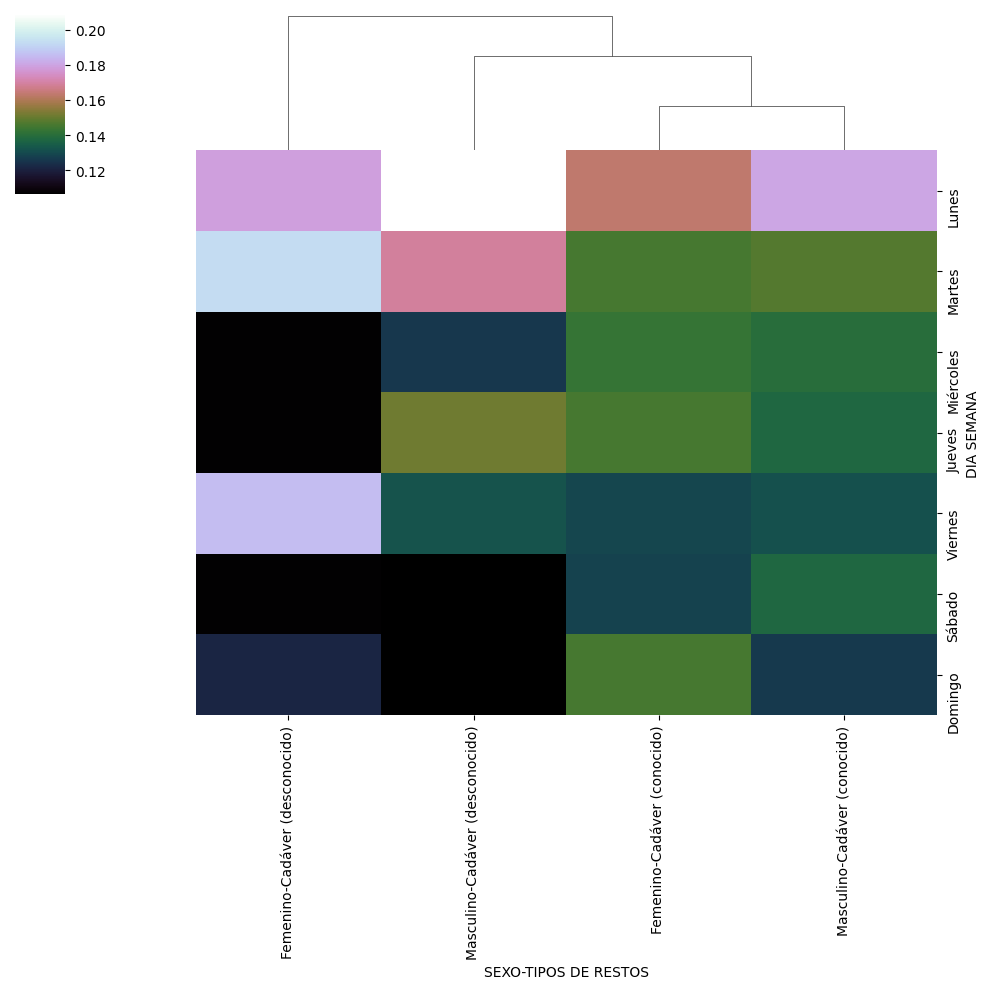

In [38]:
df_ = pd.pivot_table(df_cad, values='FECHA', index='DIA SEMANA', columns=['SEXO','TIPOS DE RESTOS'], aggfunc='count').fillna(0)
df_ = df_.loc[['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo', ]]
df_ = df_ / df_.sum()
#df_ = df_.drop('Otro',axis=1)
sns.clustermap(df_, row_cluster=False, cmap='cubehelix')
plt.show()

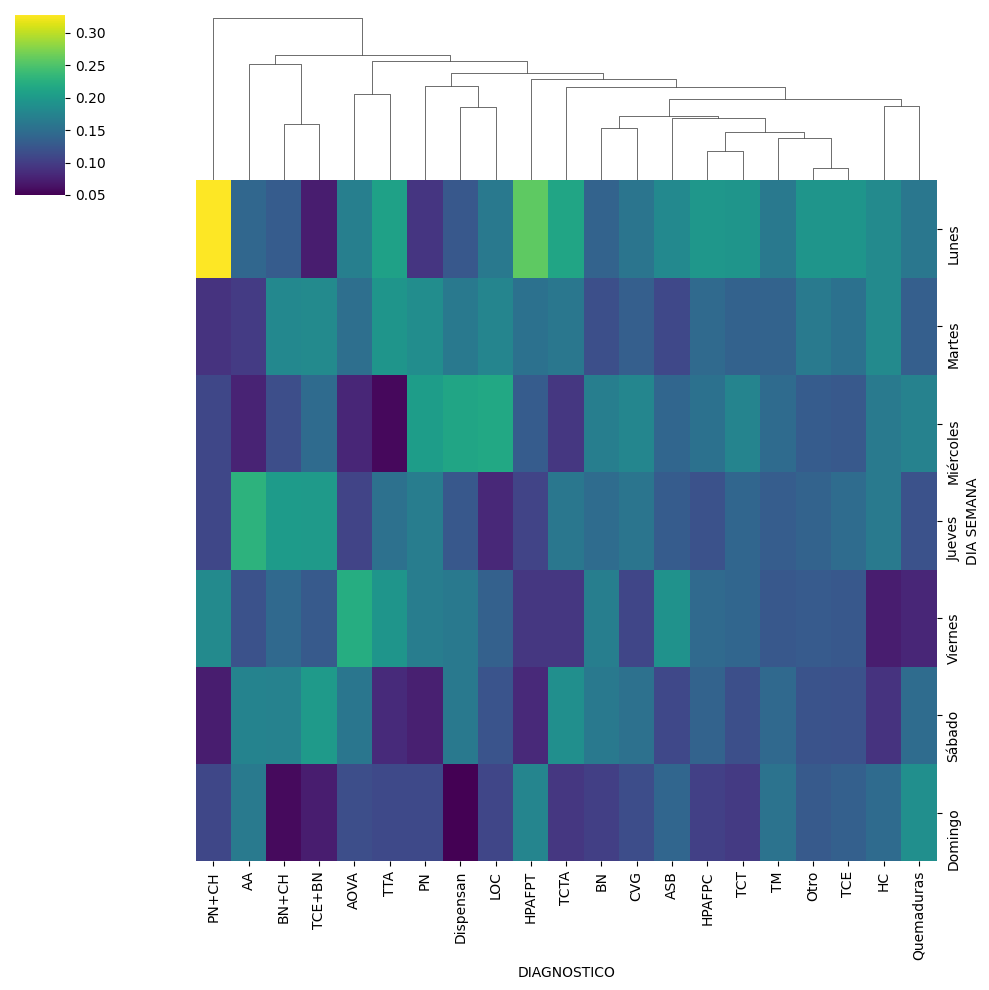

In [39]:
df_ = pd.pivot_table(df_cad, values='FECHA', index='DIA SEMANA', columns=['DIAGNOSTICO'], aggfunc='count').fillna(0)
df_ = df_.loc[['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo', ]]
df_ = df_ / df_.sum()
#df_ = df_.drop('Otro',axis=1)
sns.clustermap(df_, row_cluster=False, cmap='viridis')
plt.show()

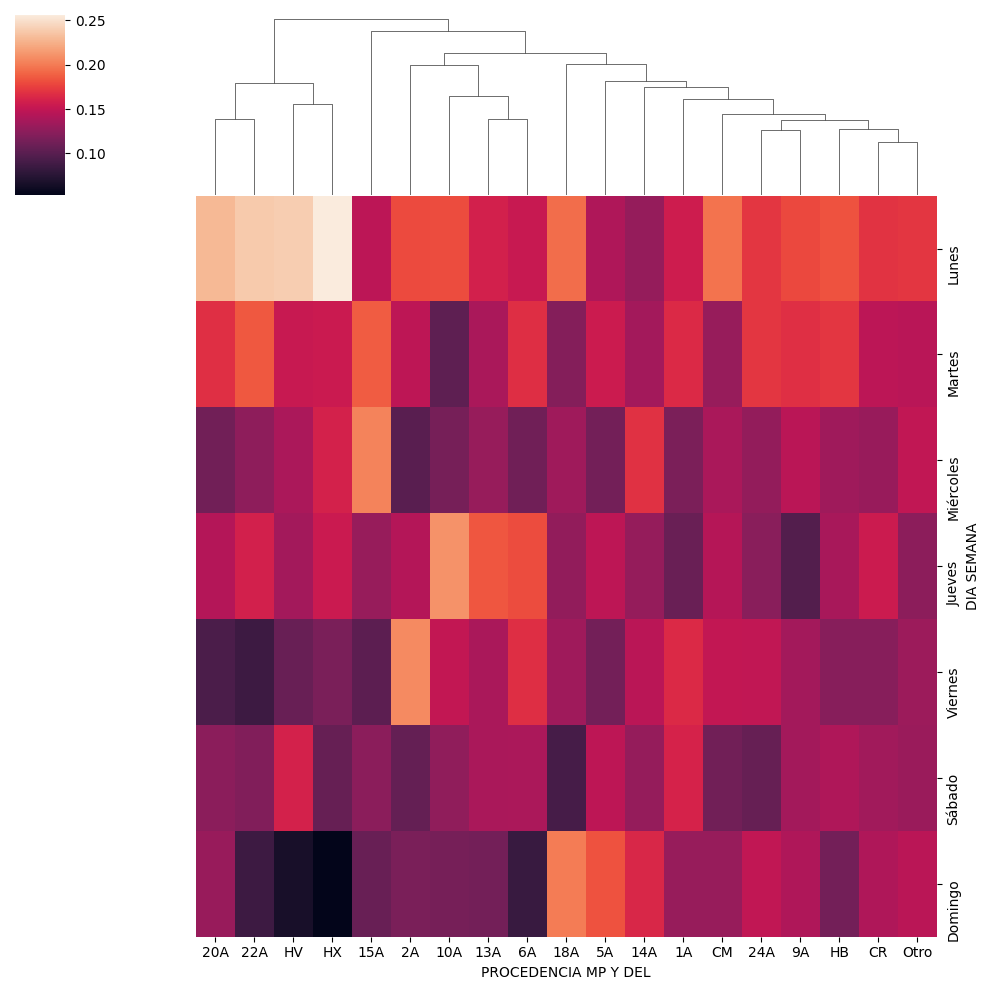

In [40]:
df_ = pd.pivot_table(df_cad, values='FECHA', index='DIA SEMANA', columns=['PROCEDENCIA MP Y DEL'], aggfunc='count').fillna(0)
df_ = df_.loc[['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo', ]]
df_ = df_ / df_.sum()
#df_ = df_.drop('Otro',axis=1)
sns.clustermap(df_, row_cluster=False)
plt.show()

### Distribución fecha vs diagnostico

3.2451923076923075

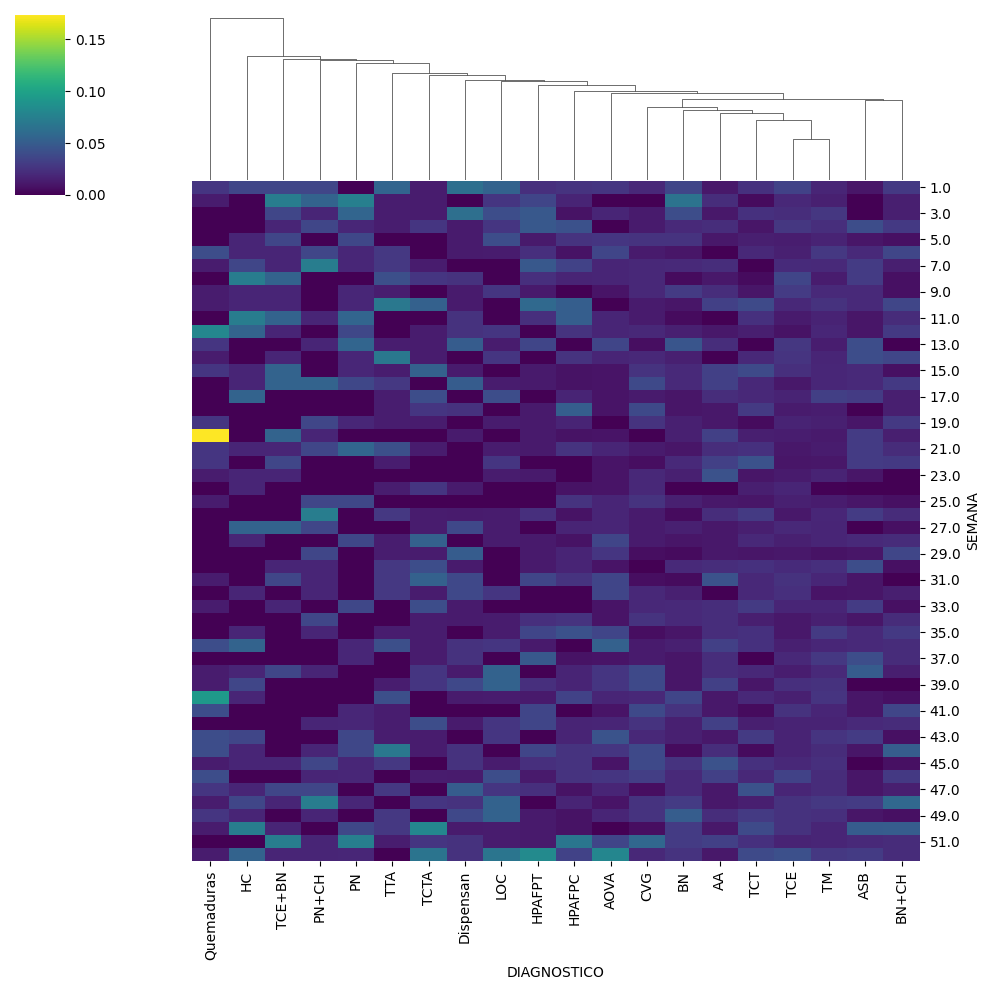

In [41]:
df_ = pd.pivot_table(df_cad, values='FECHA', index='SEMANA', columns=['DIAGNOSTICO'], aggfunc='count').fillna(0)
df_ = df_.drop('Otro',axis=1)
display(df_.stack().mean())
sns.clustermap(df_ / df_.sum(), row_cluster=False, cmap='viridis') 
plt.show()

### Fecha vs procedencia

4.464743589743589

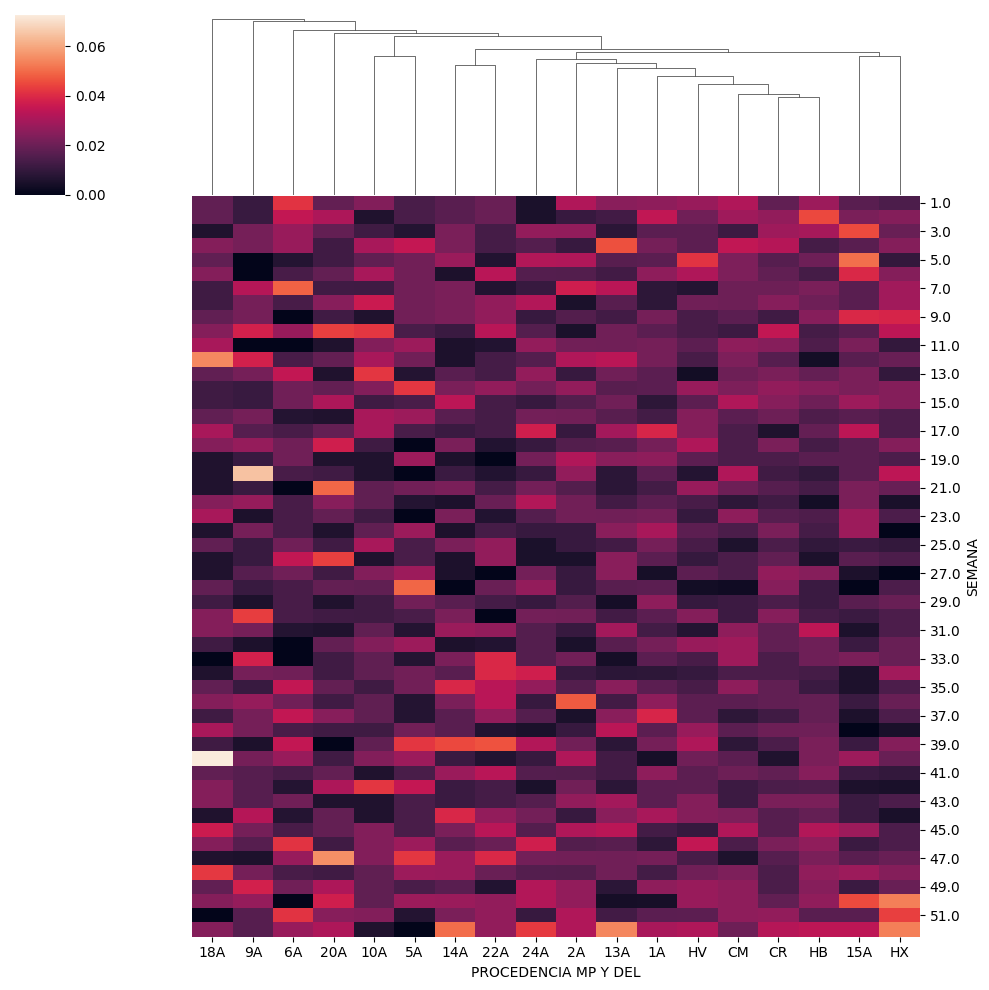

In [42]:
df_ = pd.pivot_table(df_cad, values='FECHA', index='SEMANA', columns=['PROCEDENCIA MP Y DEL'], aggfunc='count').fillna(0)
df_ = df_.drop('Otro',axis=1)
display(df_.stack().mean())
sns.clustermap(df_ / df_.sum(), row_cluster=False)
plt.show()


## Grupos

In [43]:
df_ = df_cad.groupby('AVERIGUACION PREVIA CON PROCEDENCIA').count()['SEXO']
display( df_.value_counts().sort_index() )
df_grupos = df_[df_>=4].index
df_grupos = df[df['AVERIGUACION PREVIA CON PROCEDENCIA'].isin(df_[df_>=4].index)]
df_grupos = df_grupos.drop(['NOMBRE COMPLETO', 'PROCEDENCIA MP Y DEL', 'EXP SEMEFO', 'SEMANA'], axis=1)
df_grupos.sort_values(['AVERIGUACION PREVIA CON PROCEDENCIA','FECHA'])

0       6
1    4555
2     339
3      16
4       6
5       3
7       1
9       1
Name: SEXO, dtype: int64

,APELLIDO PATERNO,APELLIDO MATERNO,NOMBRES PROPIOS,AVERIGUACION PREVIA CON PROCEDENCIA,FECHA,DIA SEMANA,TIPOS DE RESTOS,EDAD,RANGO EDAD,SEXO,DIAGNOSTICO
1436,GONZALEZ,GARCIA,ANA MARIA,13A_231,1974-01-25,Viernes,Cadáver (conocido),3.0,"(0, 5]",Femenino,TM
1437,GONZALEZ,GARCIA,J LEOPOLDO,13A_231,1974-01-25,Viernes,Cadáver (conocido),1.0,"(0, 5]",Masculino,TM
1181,ESTRADA,FRANCISCA,NaN,13A_231,1974-04-17,Miércoles,Cadáver (conocido),NaN,NaN,Femenino,PN
1182,ESTRADA,MORALES,FIDEL,13A_231,1974-04-22,Lunes,Cadáver (conocido),NaN,NaN,Masculino,TM
1063,DOMINGUEZ,RUIZ,IGNACIO,14A_1394,1974-04-10,Miércoles,Cadáver (conocido),NaN,NaN,Masculino,HPAFPA
1062,DORANTES,RAMIREZ,MIGUEL,14A_1394,1974-04-13,Sábado,Cadáver (conocido),NaN,NaN,Masculino,TCE+BN
1317,FLORES,ZUNIGA,EDGAR,14A_1394,1974-07-22,Lunes,Cadáver (conocido),3.0,"(0, 5]",Masculino,AE
1318,FLORES,ZUNIGA,DOLORES,14A_1394,1974-07-22,Lunes,Cadáver (conocido),1.0,"(0, 5]",Femenino,AE
1052,DE LA ROSA,OLMOS,MARIA LOURDES,23A_302,1974-03-23,Sábado,Cadáver (conocido),NaN,NaN,Femenino,Quemaduras
1053,DOMINGUEZ,MARTINEZ,AGUSTIN,23A_302,1974-03-28,Jueves,Cadáver (conocido),NaN,NaN,Masculino,HPAFPA


In [44]:
df_grupos.groupby('AVERIGUACION PREVIA CON PROCEDENCIA').agg(top_values_of_series_to_string)

,APELLIDO PATERNO,APELLIDO MATERNO,NOMBRES PROPIOS,FECHA,DIA SEMANA,TIPOS DE RESTOS,EDAD,RANGO EDAD,SEXO,DIAGNOSTICO
AVERIGUACION PREVIA CON PROCEDENCIA,,,,,,,,,,
13A_231,"ESTRADA (0.5), GONZALEZ (0.5)","GARCIA (0.5), FRANCISCA (0.25), MORALES (0.25)","nan (0.25), FIDEL (0.25), ANA MARIA (0.25), J LEOPOLDO (0.25)","1974-01-25 00:00:00 (0.5), 1974-04-17 00:00:00 (0.25), 1974-04-22 00:00:00 (0.25)","Viernes (0.5), Miércoles (0.25), Lunes (0.25)",Cadáver (conocido) (1.0),"nan (0.5), 3.0 (0.25), 1.0 (0.25)","nan (0.5), (0, 5] (0.5)","Femenino (0.5), Masculino (0.5)","TM (0.75), PN (0.25)"
14A_1394,"FLORES (0.5), DORANTES (0.25), DOMINGUEZ (0.25)","ZUNIGA (0.5), RAMIREZ (0.25), RUIZ (0.25)","MIGUEL (0.25), IGNACIO (0.25), EDGAR (0.25), DOLORES (0.25)","1974-07-22 00:00:00 (0.5), 1974-04-13 00:00:00 (0.25), 1974-04-10 00:00:00 (0.25)","Lunes (0.5), Sábado (0.25), Miércoles (0.25)",Cadáver (conocido) (1.0),"nan (0.5), 3.0 (0.25), 1.0 (0.25)","nan (0.5), (0, 5] (0.5)","Masculino (0.75), Femenino (0.25)","AE (0.5), TCE+BN (0.25), HPAFPA (0.25)"
23A_302,"DE LA ROSA (0.25), DOMINGUEZ (0.25), FUENTES (0.25), FUENTE (0.25)","OLMOS (0.25), MARTINEZ (0.25), MONTOYA (0.25), SAMALY (0.25)","MARIA LOURDES (0.25), AGUSTIN (0.25), MIGUEL A (0.25), PORFIRIO (0.25)","1974-06-10 00:00:00 (0.5), 1974-03-23 00:00:00 (0.25), 1974-03-28 00:00:00 (0.25)","Lunes (0.5), Sábado (0.25), Jueves (0.25)",Cadáver (conocido) (1.0),"nan (0.5), 18.0 (0.25), 20.0 (0.25)","nan (0.5), (15, 20] (0.5)","Masculino (0.75), Femenino (0.25)","HsPPAFPT (0.5), Quemaduras (0.25), HPAFPA (0.25)"
23A_343,"LAUTRE (0.25), LAURENT (0.25), MICHEL (0.25), XAVIER (0.25)","BASSET (0.75), BOSSET (0.25)","NICOLE IVONE (0.25), OLIVIERAN (0.25), F GEORGES (0.25), CRISTOPHE (0.25)","1974-06-23 00:00:00 (0.5), 1974-06-24 00:00:00 (0.25), 1974-01-23 00:00:00 (0.25)","Domingo (0.5), Lunes (0.25), Miércoles (0.25)",Cadáver (conocido) (1.0),"32.0 (0.25), 10.0 (0.25), 36.0 (0.25), 7.0 (0.25)","(05, 10] (0.5), (30, 35] (0.25), (35, 40] (0.25)","Masculino (0.75), Femenino (0.25)","TM (0.75), TCE (0.25)"
23A_445,"DOMINGUEZ (0.25), FLORES (0.25), NIETO (0.25), RAMIREZ (0.25)","ROSAS (0.25), MERLO (0.25), MARTINEZ (0.25), PORTILLO (0.25)","JESUS (0.25), JUAN (0.25), ISRAEL (0.25), SILVESTRE (0.25)","1974-08-02 00:00:00 (0.75), 1974-03-04 00:00:00 (0.25)","Viernes (0.75), Lunes (0.25)",Cadáver (conocido) (1.0),"nan (0.25), 52.0 (0.25), 15.0 (0.25), 18.0 (0.25)","nan (0.25), (50, 55] (0.25), (10, 15] (0.25), (15, 20] (0.25)",Masculino (1.0),"Electrofulguración (0.5), TCT (0.25), Electrocución (0.25)"
27A_727,"CABANAS (0.6), AVILA (0.2), AMAYA (0.2)","AMAYA (0.4), ALVAREZ (0.2), DE CABANOS (0.2), GONZALEZ (0.2)","MIGUEL (0.2), EMMA (0.2), ALICIA (0.2), SEBASTIAN (0.2), OMAR (0.2)",1974-09-30 00:00:00 (1.0),Lunes (1.0),Cadáver (conocido) (1.0),"40.0 (0.2), 43.0 (0.2), 21.0 (0.2), 45.0 (0.2), 2.0 (0.2)","(40, 45] (0.4), (35, 40] (0.2), (20, 25] (0.2), (0, 5] (0.2)","Masculino (0.6), Femenino (0.4)","Quemaduras (0.8), AS (0.2)"
5A_765,"GALVAN (0.4), CORTES (0.2), ESPINOZA (0.2), MONCADA (0.2)","GARCIA (0.4), JUANA (0.2), MONTES (0.2), nan (0.2)","LEONOR (0.2), PETRA (0.2), M TERESA (0.2), DAVID (0.2), GUADALUPE (0.2)","1974-07-08 00:00:00 (0.6), 1974-08-10 00:00:00 (0.2), 1974-07-09 00:00:00 (0.2)","Lunes (0.6), Sábado (0.2), Martes (0.2)",Cadáver (conocido) (1.0),"nan (0.2), 55.0 (0.2), 11.0 (0.2), 21.0 (0.2), 25.0 (0.2)","(20, 25] (0.4), nan (0.2), (50, 55] (0.2), (10, 15] (0.2)","Femenino (0.8), Masculino (0.2)","BN+ENT (0.2), TM (0.2), TCT (0.2), TCT+AOVA (0.2), TCTA (0.2)"
9A_866,"CAMACHO (0.5556), LESCAS (0.2222), GALVAN (0.1111), MENDOZA (0.1111)","GALVAN (0.4444), CAMACHO (0.2222), DE JESUS (0.1111), JUAREZ (0.1111), MORA (0.1111)","GEORGINA (0.1111), J MANUEL (0.1111), ESTHER (0.1111), JOSE (0.1111), MARIA DEL C (0.1111)","1974-05-15 00:00:00 (0.7778), 1974-05-14 00:00:00 (0.1111), 1974-05-16 00:00:00 (0.1111)","Miércoles (0.7778), Martes (0.1111), Jueves (0.1111)",Cadáver (conocido) (1.0),"30.0 (0

## Revision de diagnósticos específicos


In [45]:
dfs_diag = {'TODOS':df_cad,
            'TM':df_cad[df_cad['DIAGNOSTICO']=='TM'],
            'BPN+CH':df_cad[df_cad['DIAGNOSTICO'].fillna('').str.contains('CH')],
            'HPAF':df.loc[(df['DIAGNOSTICO'].fillna('').str.contains('HsPAF')) | (df['DIAGNOSTICO'].fillna('').str.contains('HPAF')),df_cad.columns]
            }
df_diag = pd.concat([df_.apply(top_values_of_series_to_string, n_top=10) for df_ in dfs_diag.values()], axis=1)
df_diag.columns = dfs_diag.keys()
df_diag.loc['FRECUENCIA'] = [df_.shape[0] for df_ in dfs_diag.values()]
df_diag.loc['EDAD PROMEDIO'] = [df_['EDAD'].mean() for df_ in dfs_diag.values()]
df_diag

,TODOS,TM,BPN+CH,HPAF
TIPOS DE RESTOS,"Cadáver (conocido) (0.8274), Cadáver (desconocido) (0.1726)","Cadáver (conocido) (0.8164), Cadáver (desconocido) (0.1836)","Cadáver (desconocido) (0.5361), Cadáver (conocido) (0.4639)","Cadáver (conocido) (0.9433), Cadáver (desconocido) (0.0544), Miembro (0.0024)"
EDAD,"nan (0.0523), 35.0 (0.0509), 40.0 (0.0492), 25.0 (0.0443), 0.0 (0.0417), 30.0 (0.0411), 45.0 (0.0406), 50.0 (0.04), 60.0 (0.0346), 55.0 (0.0286)","35.0 (0.0628), 25.0 (0.0557), 50.0 (0.0533), 40.0 (0.0498), 60.0 (0.0438), 45.0 (0.0379), nan (0.0367), 30.0 (0.0332), 20.0 (0.032), 55.0 (0.0296)","40.0 (0.1289), 45.0 (0.1186), 50.0 (0.0928), 55.0 (0.0876), 60.0 (0.0825), 35.0 (0.0825), 70.0 (0.0619), 65.0 (0.0567), 30.0 (0.0464), nan (0.0309)","25.0 (0.0898), nan (0.0804), 35.0 (0.0662), 30.0 (0.0638), 45.0 (0.052), 20.0 (0.0496), 40.0 (0.0402), 24.0 (0.0355), 22.0 (0.0331), 18.0 (0.0307)"
RANGO EDAD,"(20, 25] (0.1053), (35, 40] (0.0841), (30, 35] (0.0826), (25, 30] (0.0813), (15, 20] (0.0785), (40, 45] (0.0621), (45, 50] (0.0617), (0, 5] (0.0578), nan (0.0523), (50, 55] (0.051)","(20, 25] (0.1161), (30, 35] (0.0948), (35, 40] (0.0829), (45, 50] (0.0829), (25, 30] (0.0806), (15, 20] (0.0782), (40, 45] (0.0592), (55, 60] (0.0569), (0, 5] (0.0521), (50, 55] (0.0474)","(35, 40] (0.1701), (40, 45] (0.134), (45, 50] (0.1237), (30, 35] (0.1134), (55, 60] (0.0979), (50, 55] (0.0928), (60, 65] (0.067), (65, 70] (0.0619), (25, 30] (0.0464), (20, 25] (0.0412)","(20, 25] (0.2009), (25, 30] (0.1489), (15, 20] (0.1466), (30, 35] (0.1206), (35, 40] (0.0827), nan (0.0804), (40, 45] (0.0757), (45, 50] (0.0284), (60, 65] (0.0213), (50, 55] (0.0189)"
SEXO,"Masculino (0.7805), Femenino (0.2174), nan (0.0021)","Masculino (0.7713), Femenino (0.2287)","Masculino (0.8866), Femenino (0.1134)","Masculino (0.9054), Femenino (0.0946)"
FECHA,"1974-12-27 00:00:00 (0.0064), 1974-12-26 00:00:00 (0.0054), 1974-03-07 00:00:00 (0.0052), 1974-12-25 00:00:00 (0.005), 1974-09-30 00:00:00 (0.0049), 1974-11-14 00:00:00 (0.0047), 1974-02-11 00:00:00 (0.0047), 1974-12-11 00:00:00 (0.0047), 1974-12-09 00:00:00 (0.0047), 1974-04-22 00:00:00 (0.0047)","1974-04-24 00:00:00 (0.0095), 1974-12-01 00:00:00 (0.0095), 1974-09-11 00:00:00 (0.0083), 1974-11-30 00:00:00 (0.0083), 1974-04-22 00:00:00 (0.0083), 1974-12-27 00:00:00 (0.0071), 1974-11-16 00:00:00 (0.0071), 1974-11-22 00:00:00 (0.0071), 1974-12-02 00:00:00 (0.0071), 1974-02-09 00:00:00 (0.0071)","1974-12-13 00:00:00 (0.0206), 1974-11-27 00:00:00 (0.0155), 1974-07-17 00:00:00 (0.0155), 1974-02-09 00:00:00 (0.0155), 1974-05-06 00:00:00 (0.0155), 1974-09-02 00:00:00 (0.0155), 1974-02-07 00:00:00 (0.0155), 1974-01-23 00:00:00 (0.0155), 1974-10-31 00:00:00 (0.0155), 1974-11-25 00:00:00 (0.0155)","1974-03-04 00:00:00 (0.0165), 1974-12-19 00:00:00 (0.0142), 1974-08-19 00:00:00 (0.0118), 1974-12-13 00:00:00 (0.0118), 1974-04-29 00:00:00 (0.0118), 1974-12-25 00:00:00 (0.0118), 1974-07-30 00:00:00 (0.0118), 1974-02-15 00:00:00 (0.0118), 1974-09-04 00:00:00 (0.0095), 1974-12-26 00:00:00 (0.0095)"
SEMANA,"52.0 (0.0308), 50.0 (0.0243), 1.0 (0.0237), 51.0 (0.0228), 45.0 (0.0224), 2.0 (0.0222), 48.0 (0.0221), 49.0 (0.0219), 39.0 (0.0215), 7.0 (0.0215)","17.0 (0.032), 35.0 (0.0296), 37.0 (0.0284), 52.0 (0.0284), 6.0 (0.0284), 48.0 (0.0284), 3.0 (0.0273), 43.0 (0.0261), 40.0 (0.0261), 10.0 (0.0249)","48.0 (0.0619), 44.0 (0.0412), 26.0 (0.0361), 16.0 (0.0361), 29.0 (0.0361), 6.0 (0.0361), 50.0 (0.0361), 7.0 (0.0309), 19.0 (0.0309), 4.0 (0.0309)","52.0 (0.0426), 10.0 (0.0378), 51.0 (0.0355), 18.0 (0.0331), 7.0 (0.0307), 4.0 (0.0284), 50.0 (0.026), 34.0 (0.026), 31.0 (0.026), 8.0 (0.0236)"
DIA SEMANA,"Lunes (0.1806), Martes (0.1511), Jueves (0.1397), Miércoles (0.1368), Viernes (0.132), Sábado (0.1299), Domingo (0.1266), nan (0.0034)","Lunes (0.1623), Domingo (0.1552), Miércoles (0.1457), Sábado (0.1434), Martes (0.1374), Jueves (0.1303), Viernes (0.1256)","Lunes (0.1856), Jueves (0.1753), Martes (0.1546), Viernes (0.1546), Sábado (0.144

## Hipotesis

### Mujeres por arma de fuego

In [46]:
df[((df['DIAGNOSTICO'].fillna('').str.contains('HPAF')) | (df['DIAGNOSTICO'].fillna('').str.contains('HsPA'))) 
   & (df['SEXO']=='Femenino') ].sort_values('FECHA')

,NOMBRE COMPLETO,APELLIDO PATERNO,APELLIDO MATERNO,NOMBRES PROPIOS,PROCEDENCIA MP Y DEL,AVERIGUACION PREVIA CON PROCEDENCIA,EXP SEMEFO,FECHA,SEMANA,DIA SEMANA,TIPOS DE RESTOS,EDAD,RANGO EDAD,SEXO,DIAGNOSTICO
21,ALCANTARA DE LA PERALTA EUFRACIA,ALCANTARA,DE LA PERALTA,EUFRACIA,15A,15A_123,236,1974-01-15,3.0,Martes,Cadáver (conocido),40.0,"(35, 40]",Femenino,HPAFPT
1995,HERNANDEZ DE MARTINEZ ENRIQUETA,HERNANDEZ,NaN,ENRIQUETA,14A,14A_120,427,1974-01-26,4.0,Sábado,Cadáver (conocido),36.0,"(35, 40]",Femenino,HPAFPC
3257,OLIVARES DE MUNOZ ISABEL,OLIVARES,NaN,ISABEL,CR,CR_87,443,1974-01-27,4.0,Domingo,Cadáver (conocido),30.0,"(25, 30]",Femenino,HPAFPC
4329,WALTZ MATHIEU JAQUELINA,WALTZ,MATHIEU,JAQUELINA,CR,CR_356,1540,1974-01-30,5.0,Miércoles,Cadáver (conocido),30.0,"(25, 30]",Femenino,HPAFPA
2632,MARTINEZ DE ARRIAGA GRACIELA,MARTINEZ,NaN,GRACIELA,18A,18A_113,501,1974-01-30,5.0,Miércoles,Cadáver (conocido),30.0,"(25, 30]",Femenino,HPAFPC
2635,MUNOZ RODRIGUEZ SORA,MUNOZ,RODRIGUEZ,SORA,18A,18A_127,518,1974-02-01,5.0,Viernes,Cadáver (conocido),30.0,"(25, 30]",Femenino,HPAFPA
4538,DESCONOCIDO,NaN,NaN,NaN,PGR,PGR_746,794,1974-02-15,7.0,Viernes,Cadáver (desconocido),19.0,"(15, 20]",Femenino,HPAFPC
4539,DESCONOCIDO,NaN,NaN,NaN,PGR,PGR_746,795,1974-02-15,7.0,Viernes,Cadáver (desconocido),25.0,"(20, 25]",Femenino,HsPAPPTyA
4251,TILIANO CASTILLO LEONOR,TILIANO,CASTILLO,LEONOR,CM,CM_281,979,1974-02-26,9.0,Martes,Cadáver (conocido),49.0,"(45, 50]",Femenino,HPAFPA
1501,GALINDO DE ROLDAN MARIA,GALINDO,NaN,MARIA,CR,CR_364,1132,1974-03-06,10.0,Miércoles,Cadáver (conocido),45.0,"(40, 45]",Femenino,HPAFPC


## Comparación INEGI


<AxesSubplot: ylabel='Rango edad'>

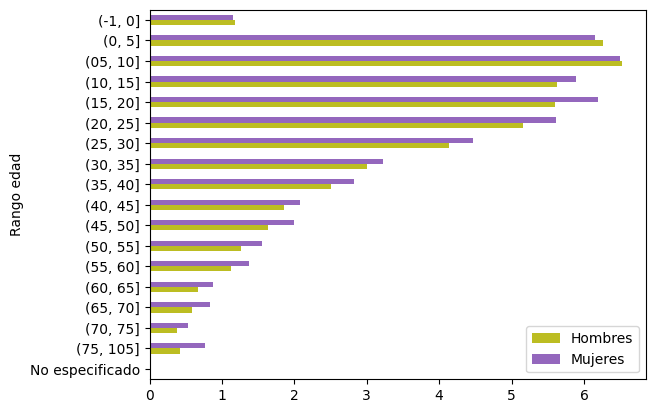

In [47]:
import re
import pandas as pd

file_inegi = "data_raw/inegi_censo1980_poblacion_edad_sexo.csv"
df_inegi = pd.read_csv(file_inegi)
df_1980 = df_inegi[df_inegi['Entidad']=='09  Distrito Federal'].groupby('Rango edad').sum(numeric_only=True)
df_1980 = df_1980/df_1980.loc['Total','Total']*100
df_1980 = df_1980.drop('Total').drop('Total', axis=1).sort_index(ascending=False)
df_1980.plot.barh(color=['tab:olive','tab:purple',])


<AxesSubplot: ylabel='Rango edad'>

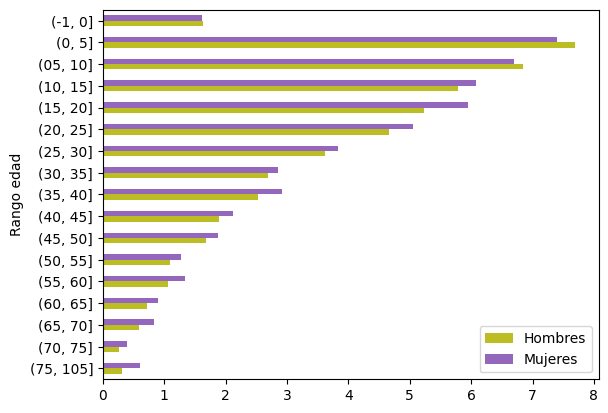

In [48]:
file_inegi = "data_raw/inegi_censo1970_poblacion_edad_sexo.csv"
df_inegi = pd.read_csv(file_inegi)
df_1970 = df_inegi[df_inegi['Entidad']=='Distrito Federal'].groupby('Rango edad').sum(numeric_only=True)
df_1970 = df_1970/df_1970.loc['Total','Total']*100
df_1970 = df_1970.drop('Total').drop('Total', axis=1).sort_index(ascending=False)
df_1970.plot.barh(color=['tab:olive','tab:purple',])


<AxesSubplot: ylabel='RANGO EDAD'>

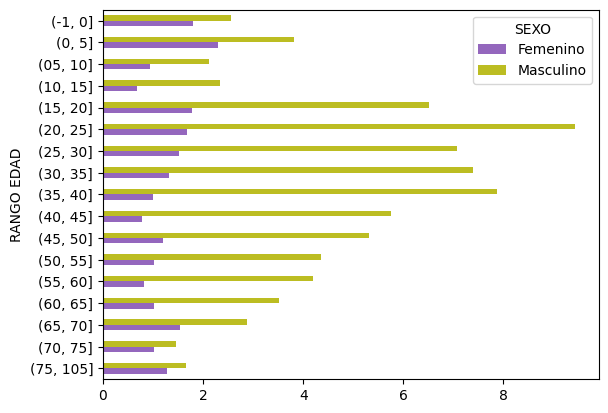

In [49]:
df_1974 = pd.pivot_table(df_cad, values='TIPOS DE RESTOS', index='RANGO EDAD', columns='SEXO', aggfunc='count')
df_1974.loc['Total'] = df_1974.sum()
df_1974['Total'] = df_1974.sum(axis=1)
df_1974 = df_1974/df_1974.loc['Total','Total']*100
df_1974 = df_1974.drop('Total').drop('Total', axis=1).sort_index(ascending=False)
df_1974.plot.barh(color=['tab:purple','tab:olive'])
